# What should a good pickup forecast get right?

The [data engineering notebook](data_engineering1_organized_v3.ipynb) explains why I use completed pickups as the target. Here I want to find the hours where a simple forecast would work and the hours where I would expect it to miss.

Before choosing a model, I want to understand what it will be asked to predict. A citywide average mixes airports, residential neighborhoods, busy evenings, and hours with no pickups. I expect those differences to matter more than a single summary score suggests.

I'll start with the target distribution, then separate location and time, inspect unusual activity, and see how well the historical lags describe it. After that, I'll check weather coverage and whether the later validation period looks different from training.


## 1. Am I looking at the same rows the model will see?

I'll use the saved production table, feature manifest, and split manifest. That keeps this exploration attached to the same problem the models will receive, rather than rebuilding a slightly different version along the way.


In [ ]:
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
import pyarrow.compute as pc
import pyarrow.dataset as ds
import pyarrow.parquet as pq
import seaborn as sns
import matplotlib.pyplot as plt

from IPython.display import display
from matplotlib.ticker import (
    FuncFormatter,
    PercentFormatter,
)


# Configuring readable table output
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", "{:,.3f}".format)

# Configuring a consistent presentation-ready chart theme
sns.set_theme(
    context="notebook",
    style="white",
    palette="deep",
    font_scale=1.0,
)

plt.rcParams.update({
    "figure.figsize": (10, 8),
    "figure.dpi": 820,
    "savefig.dpi": 820,
    "axes.titleweight": "bold",
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "axes.edgecolor": "#D1D5DB",
    "axes.linewidth": 0.8,
    "grid.color": "#E5E7EB",
    "grid.linewidth": 0.8,
    "grid.alpha": 0.7,
    "legend.frameon": False,
})

print("EDA packages and display settings are loaded.")

EDA packages and display settings are loaded.


In [ ]:
def find_project_root(start_path: Path) -> Path:
    """Finding the repository root from any directory inside the project."""
    resolved_start = start_path.resolve()

    for candidate in (resolved_start, *resolved_start.parents):
        has_data = (candidate / "data").is_dir()
        has_notebooks = (candidate / "notebooks").is_dir()

        if has_data and has_notebooks:
            return candidate

    raise FileNotFoundError(
        "Could not locate a project root containing "
        "both 'data' and 'notebooks' directories."
    )


def validate_required_paths(required_paths: dict) -> None:
    """Checking that every required project artifact exists."""
    missing_paths = {
        name: path
        for name, path in required_paths.items()
        if not path.exists()
    }

    if missing_paths:
        missing_text = "\n".join(
            f"- {name}: {path}"
            for name, path in missing_paths.items()
        )
        raise FileNotFoundError(
            f"Required project artifacts are missing:\n{missing_text}"
        )

    print(f"Required paths found: {len(required_paths)}")


def build_parquet_metadata_table(
    parquet_paths: list[Path],
    relative_to: Path,
) -> pd.DataFrame:
    """Collecting file-level metadata without loading Parquet rows."""
    if not parquet_paths:
        raise FileNotFoundError("No Parquet files were found.")

    reference_schema = pq.ParquetFile(
        parquet_paths[0]
    ).schema_arrow

    metadata_records = []

    for parquet_path in parquet_paths:
        parquet_file = pq.ParquetFile(parquet_path)
        schema = parquet_file.schema_arrow

        metadata_records.append({
            "file": str(parquet_path.relative_to(relative_to)),
            "rows": parquet_file.metadata.num_rows,
            "row_groups": parquet_file.metadata.num_row_groups,
            "columns": len(schema),
            "size_mb": parquet_path.stat().st_size / 1024**2,
            "schema_matches_reference": schema.equals(
                reference_schema
            ),
        })

    return pd.DataFrame(metadata_records)


def format_large_number(value, position=None) -> str:
    """Formatting large chart-axis values with readable units."""
    absolute_value = abs(value)

    if absolute_value >= 1_000_000_000:
        return f"{value / 1_000_000_000:.1f}B"
    if absolute_value >= 1_000_000:
        return f"{value / 1_000_000:.1f}M"
    if absolute_value >= 1_000:
        return f"{value / 1_000:.1f}K"

    return f"{value:,.0f}"


large_number_formatter = FuncFormatter(format_large_number)

print("Reusable EDA functions defined.")

Reusable EDA functions defined.


In [ ]:
# Locating the project from the current notebook directory
PROJECT_ROOT = find_project_root(Path.cwd())

PRODUCTION_DATA_ROOT = (
    PROJECT_ROOT
    / "data"
    / "gold"
    / "production_model"
    / "hourly_zone_horizon_features"
    / "availability_delay=7h"
)

PRODUCTION_MANIFEST_DIR = (
    PRODUCTION_DATA_ROOT
    / "manifests"
)

PRODUCTION_AUDIT_DIR = (
    PRODUCTION_DATA_ROOT
    / "audit"
)

FEATURE_MANIFEST_PATH = (
    PRODUCTION_MANIFEST_DIR
    / "production_model_feature_manifest.parquet"
)

SPLIT_MANIFEST_PATH = (
    PRODUCTION_MANIFEST_DIR
    / "production_forecast_origin_split_manifest.parquet"
)

PARTITION_AUDIT_PATH = (
    PRODUCTION_AUDIT_DIR
    / "production_feature_partition_audit.parquet"
)

# Finding the monthly production feature files
production_partition_paths = sorted(
    PRODUCTION_DATA_ROOT.glob(
        "year=*/month=*/production_features_*.parquet"
    )
)

# Validating the required production artifacts
required_paths = {
    "production dataset directory": PRODUCTION_DATA_ROOT,
    "feature manifest": FEATURE_MANIFEST_PATH,
    "split manifest": SPLIT_MANIFEST_PATH,
    "partition audit": PARTITION_AUDIT_PATH,
}

validate_required_paths(required_paths)

print("Project root:", PROJECT_ROOT)
print("Production data root:", PRODUCTION_DATA_ROOT)
print("Monthly Parquet partitions:", len(production_partition_paths))

assert len(production_partition_paths) == 23, (
    "Expected 23 monthly production partitions, "
    f"but found {len(production_partition_paths)}."
)

print("Production path validation passed: True")

Required paths found: 4
Monthly Parquet partitions: 23
Production path validation passed: True


In [ ]:
# Collecting metadata from the monthly Parquet files
partition_metadata = build_parquet_metadata_table(
    parquet_paths=production_partition_paths,
    relative_to=PROJECT_ROOT,
)

# Summarizing the complete production dataset
dataset_metadata_summary = pd.DataFrame({
    "metric": [
        "Parquet partitions",
        "Total rows",
        "Columns per partition",
        "Total row groups",
        "Total compressed size (MB)",
        "Identical schemas",
    ],
    "value": [
        len(partition_metadata),
        int(partition_metadata["rows"].sum()),
        int(partition_metadata["columns"].iloc[0]),
        int(partition_metadata["row_groups"].sum()),
        round(partition_metadata["size_mb"].sum(), 2),
        bool(
            partition_metadata[
                "schema_matches_reference"
            ].all()
        ),
    ],
})

display(dataset_metadata_summary)

# Showing the chronological endpoints without printing all files
display(
    partition_metadata.loc[
        [0, len(partition_metadata) - 1],
        ["file", "rows", "row_groups", "size_mb"],
    ].rename(
        index={
            0: "First partition",
            len(partition_metadata) - 1: "Last partition",
        }
    )
)

assert len(partition_metadata) == 23
assert partition_metadata["rows"].sum() == 26_117_478
assert partition_metadata["columns"].eq(53).all()
assert partition_metadata["schema_matches_reference"].all()

print("Production Parquet metadata validation passed: True")

,metric,value
0,Parquet partitions,23
1,Total rows,26117478
2,Columns per partition,53
3,Total row groups,45
4,Total compressed size (MB),126.900
5,Identical schemas,True


,file,rows,row_groups,size_mb
First partition,data\gold\production_model\hourly_zone_horizon...,822138,1,3.630
Last partition,data\gold\production_model\hourly_zone_horizon...,1133004,2,5.698


Production Parquet metadata validation passed: True


### What is in the forecasting table?

The table has about 26.1 million rows across 23 monthly files, all with the same 53-column schema. That is the expected handoff from weather preparation. Next I want to make sure I understand what those rows and columns represent before plotting them.


In [ ]:
# Connecting the monthly files as one logical PyArrow dataset
production_dataset = ds.dataset(
    [str(path) for path in production_partition_paths],
    format="parquet",
)

# Loading the small saved manifests
feature_manifest = pd.read_parquet(FEATURE_MANIFEST_PATH)
split_manifest = pd.read_parquet(SPLIT_MANIFEST_PATH)

# Converting saved split timestamps consistently to UTC
split_time_columns = [
    "forecast_origin_utc",
    "target_start_utc",
    "target_end_utc",
]

for column in split_time_columns:
    split_manifest[column] = pd.to_datetime(
        split_manifest[column],
        utc=True,
    )

# Summarizing feature roles
feature_role_summary = (
    feature_manifest
    .groupby("role", as_index=False)
    .agg(
        columns=("column_name", "count"),
        primary_model_columns=("use_in_primary_model", "sum"),
    )
    .sort_values("role")
    .reset_index(drop=True)
)

# Summarizing origin assignments without reading dataset rows
split_summary = (
    split_manifest
    .groupby("split", as_index=False)
    .agg(
        origins=("forecast_origin_utc", "size"),
        represented_rows=("rows", "sum"),
    )
    .sort_values("split")
    .reset_index(drop=True)
)

display(feature_role_summary)
display(split_summary)

# Identifying approved categorical features
categorical_features = feature_manifest.loc[
    feature_manifest["use_in_primary_model"]
    & feature_manifest["modeling_type"].eq("categorical"),
    "column_name",
].tolist()

# Checking for prohibited observed target-hour weather
observed_weather_columns = {
    "temperature_f",
    "precipitation_in",
    "rain_in",
    "snowfall_in",
    "wind_speed_mph",
}

unexpected_observed_weather = sorted(
    observed_weather_columns
    & set(production_dataset.schema.names)
)

print("Manifest columns:", len(feature_manifest))
print("Dataset schema columns:", len(production_dataset.schema.names))
print("Primary categorical features:", categorical_features)
print("Observed-weather columns found:", unexpected_observed_weather)

assert len(feature_manifest) == 53
assert feature_manifest["column_name"].is_unique
assert set(feature_manifest["column_name"]) == set(
    production_dataset.schema.names
)
assert feature_manifest["use_in_primary_model"].sum() == 30

assert feature_manifest["role"].value_counts().to_dict() == {
    "primary_feature": 30,
    "excluded_metadata": 18,
    "key": 3,
    "sensitivity_flag": 1,
    "target": 1,
}

assert split_manifest["forecast_origin_utc"].is_unique
assert split_manifest["split"].value_counts().to_dict() == {
    "training": 12_208,
    "test": 2_178,
    "validation": 2_153,
    "purged_boundary": 12,
}

assert split_manifest["rows"].sum() == 26_117_478
assert unexpected_observed_weather == []

print("Feature and split manifest validation passed: True")

,role,columns,primary_model_columns
0,excluded_metadata,18,0
1,key,3,0
2,primary_feature,30,30
3,sensitivity_flag,1,0
4,target,1,0


,split,origins,represented_rows
0,purged_boundary,12,18936
1,test,2178,3436884
2,training,12208,19264224
3,validation,2153,3397434


Manifest columns: 53
Dataset schema columns: 53
Primary categorical features: ['day_of_week', 'forecast_horizon', 'hour_of_day', 'location_id', 'month']
Observed-weather columns found: []
Feature and split manifest validation passed: True


### Which columns and dates belong in modeling?

Only 30 of the stored columns are model inputs. The rest include the target, keys, metadata, and a daylight-saving flag. I'll keep the manifest's roles and date ranges instead of choosing a new feature list or split for this exploration.


### Letting DuckDB do the counting

Most questions here can be answered with a small grouped table. I'll let DuckDB scan the Parquet files and bring only those summaries into pandas. There is no need to hold the full table in memory just to count zeros or draw an hourly curve.


In [ ]:
# Identifying the year-month combinations used by training origins
training_origins = split_manifest.loc[
    split_manifest["split"].eq("training"),
    "forecast_origin_utc",
]

training_year_months = set(
    zip(
        training_origins.dt.year,
        training_origins.dt.month,
    )
)

# Selecting only monthly files that overlap the training period
training_partition_paths = []

for path in production_partition_paths:
    year = int(
        next(
            part.split("=")[1]
            for part in path.parts
            if part.startswith("year=")
        )
    )
    month = int(
        next(
            part.split("=")[1]
            for part in path.parts
            if part.startswith("month=")
        )
    )

    if (year, month) in training_year_months:
        training_partition_paths.append(path)

print("Training year-months:", len(training_year_months))
print("Training Parquet files:", len(training_partition_paths))
print("First training file:", training_partition_paths[0].name)
print("Last training file:", training_partition_paths[-1].name)

assert len(training_partition_paths) == 17

print("Training partition selection passed: True")

Training year-months: 17
Training Parquet files: 17
First training file: production_features_202408.parquet
Last training file: production_features_202512.parquet
Training partition selection passed: True


In [ ]:
# Creating an in-memory DuckDB connection
duckdb_connection = duckdb.connect(database=":memory:")

# Registering the split manifest for use in SQL queries
duckdb_connection.register(
    "split_manifest_sql",
    split_manifest,
)

# Checking the tables available to DuckDB
duckdb_tables = duckdb_connection.execute("""
    SHOW TABLES
""").df()

display(duckdb_tables)

assert "split_manifest_sql" in duckdb_tables["name"].tolist()

print("DuckDB connection and manifest registration passed: True")

,name
0,split_manifest_sql


DuckDB connection and manifest registration passed: True


In [ ]:
# Setting DuckDB timestamp displays to UTC
duckdb_connection.execute("""
    SET TimeZone = 'UTC'
""")

duckdb_timezone = duckdb_connection.execute("""
    SELECT current_setting('TimeZone') AS timezone
""").df()

display(duckdb_timezone)

assert duckdb_timezone.loc[0, "timezone"] == "UTC"



,timezone
0,UTC


In [ ]:
# Creating the training-only DuckDB view
training_file_paths_sql = ",\n".join(
    f"'{path.as_posix()}'"
    for path in training_partition_paths
)

duckdb_connection.execute(f"""
    CREATE OR REPLACE VIEW training_forecast_rows AS
    SELECT p.*
    FROM read_parquet(
        [{training_file_paths_sql}],
        union_by_name = true,
        hive_partitioning = false
    ) AS p
    INNER JOIN split_manifest_sql AS s
        ON p.forecast_origin_utc = s.forecast_origin_utc
    WHERE s.split = 'training'
""")



## 2. What does a typical zone-hour look like?

Think about the 9 a.m. pickup count in one zone. I could have forecast that count at 8 a.m., 7 a.m., or earlier. When I describe how busy 9 a.m. was, I count the observed outcome once. When I check the forecast inputs, I keep the separate forecasts because they could have used different information.

The same pickup outcome appears in several forecasts made at different origins. For the target distribution, I want to count that realized zone-hour once. Otherwise the forecast layout could change the apparent distribution of activity. Weather will need a different view later because its selected run depends on issuance.


In [ ]:
# Creating one demand record per target hour and zone
duckdb_connection.execute("""
    CREATE OR REPLACE VIEW training_demand AS

    SELECT
        target_hour_utc,
        target_hour_local,
        location_id,
        total_pickups,
        hour_of_day,
        day_of_week,
        month,
        is_weekend

    FROM training_forecast_rows

    QUALIFY ROW_NUMBER() OVER (
        PARTITION BY target_hour_utc, location_id
        ORDER BY forecast_horizon
    ) = 1
""")



In [ ]:
# Summarizing hourly zone-level demand
demand_summary = duckdb_connection.execute("""
    SELECT
        COUNT(*) AS observations,
        ROUND(AVG(total_pickups), 2) AS mean_pickups,
        MEDIAN(total_pickups) AS median_pickups,
        ROUND(STDDEV_SAMP(total_pickups), 2) AS standard_deviation,
        MIN(total_pickups) AS minimum_pickups,
        MAX(total_pickups) AS maximum_pickups,
        ROUND(
            100.0 * COUNT(*) FILTER (WHERE total_pickups = 0)
            / COUNT(*),
            2
        ) AS zero_demand_percent
    FROM training_demand
""").df()

display(demand_summary)

,observations,mean_pickups,median_pickups,standard_deviation,minimum_pickups,maximum_pickups,zero_demand_percent
0,3212019,104.920,71.000,116.350,0,1971,4.290


### Why is the average higher than the median?

The mean is about 105 pickups, but the median is only 71. That gap is the first sign that a smaller number of busy hours pull the average upward. I'll look at percentiles next to see how far that upper tail extends.


In [ ]:
# Calculating demand percentiles
demand_percentiles = duckdb_connection.execute("""
    SELECT
        QUANTILE_CONT(total_pickups, 0.25) AS p25,
        QUANTILE_CONT(total_pickups, 0.50) AS p50,
        QUANTILE_CONT(total_pickups, 0.75) AS p75,
        QUANTILE_CONT(total_pickups, 0.90) AS p90,
        QUANTILE_CONT(total_pickups, 0.95) AS p95,
        QUANTILE_CONT(total_pickups, 0.99) AS p99,
        QUANTILE_CONT(total_pickups, 0.999) AS p999
    FROM training_demand
""").df()

display(demand_percentiles)

,p25,p50,p75,p90,p95,p99,p999
0,26.000,71.000,147.000,243.000,315.000,541.000,991.000


### How unusual are the busiest hours?

Most hours are well below the largest counts: 90% have no more than 243 pickups, while the top 0.1% exceeds roughly 991. I don't want to remove those automatically. A thousand pickups could be unusual in one zone and quite plausible in another.


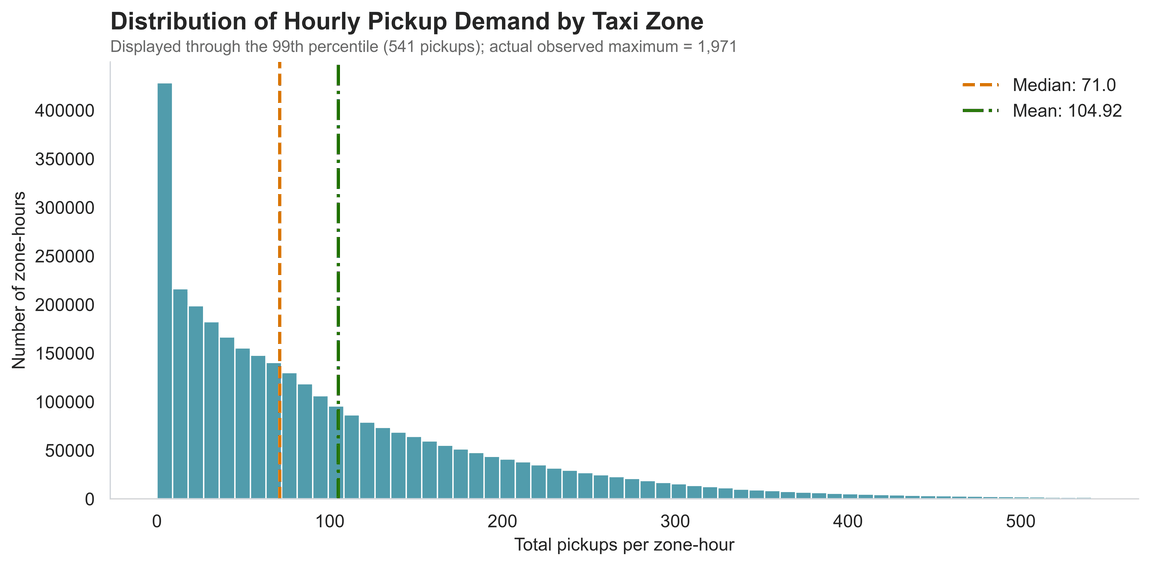

In [ ]:
# Aggregating pickup frequencies through the 99th percentile
p99_pickups = int(demand_percentiles.loc[0, "p99"])

demand_histogram = duckdb_connection.execute(f"""
    SELECT
        total_pickups,
        COUNT(*) AS frequency
    FROM training_demand
    WHERE total_pickups <= {p99_pickups}
    GROUP BY total_pickups
    ORDER BY total_pickups
""").df()

# Visualizing the central demand distribution
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    data=demand_histogram,
    x="total_pickups",
    weights="frequency",
    bins=60,
    color="#177B91",
    edgecolor="white",
    ax=ax,
)

ax.axvline(
    demand_summary.loc[0, "median_pickups"],
    color="#D97706",
    linestyle="--",
    linewidth=2,
    label=f"Median: {demand_summary.loc[0, "median_pickups"]}",
)

ax.axvline(
    demand_summary.loc[0, "mean_pickups"],
    color="#277605",
    linestyle="-.",
    linewidth=2,
    label=f"Mean: {demand_summary.loc[0, "mean_pickups"]}",
)

ax.set_title(
    "Distribution of Hourly Pickup Demand by Taxi Zone",
    loc="left",
    fontsize=15,
    fontweight="bold",
    pad=20,
)

ax.text(
    0,
    1.015,
    "Displayed through the 99th percentile (541 pickups); "
    "actual observed maximum = 1,971",
    transform=ax.transAxes,
    fontsize=10,
    color="dimgray",
    ha="left",
    va="bottom",
  
)

ax.set(
    xlabel="Total pickups per zone-hour",
    ylabel="Number of zone-hours",
)

ax.legend()
sns.despine()
plt.tight_layout()
plt.show()

The histogram makes the skew easier to see. Most zone-hours sit at low or moderate counts, with a long tail on the right. I'll separate zones before deciding what deserves investigation, because the pooled distribution combines very different places.


In [ ]:
# Calculating zero-demand rates by taxi zone
zone_zero_rates = duckdb_connection.execute("""
    SELECT
        location_id,
        COUNT(*) AS observed_hours,
        COUNT(*) FILTER (
            WHERE total_pickups = 0
        ) AS zero_demand_hours,
        ROUND(
            100.0 * COUNT(*) FILTER (WHERE total_pickups = 0)
            / COUNT(*),
            2
        ) AS zero_demand_percent,
        ROUND(AVG(total_pickups), 2) AS mean_pickups
    FROM training_demand
    GROUP BY location_id
    ORDER BY zero_demand_percent DESC, location_id
""").df()

display(zone_zero_rates.head(15))

,location_id,observed_hours,zero_demand_hours,zero_demand_percent,mean_pickups
0,103,12213,12213,100.000,0.000
1,104,12213,12213,100.000,0.000
2,1,12213,12189,99.800,0.000
3,105,12213,12148,99.470,0.010
4,199,12213,12121,99.250,0.010
5,110,12213,11577,94.790,0.050
6,2,12213,11424,93.540,0.070
7,99,12213,6735,55.150,0.670
8,253,12213,6471,52.980,1.040
9,8,12213,5767,47.220,1.110


### Where do hours with no pickups show up?

Zero pickups are also unevenly distributed. Some zones are nearly always quiet, while others rarely have a zero hour. That makes me question whether one global model will handle the quietest places as well as it handles the rest.


In [ ]:
# Measuring the concentration of zero demand
zero_concentration = duckdb_connection.execute("""
    WITH zone_summary AS (
        SELECT
            location_id,
            COUNT(*) FILTER (
                WHERE total_pickups = 0
            ) AS zero_hours,
            100.0 * COUNT(*) FILTER (
                WHERE total_pickups = 0
            ) / COUNT(*) AS zero_percent
        FROM training_demand
        GROUP BY location_id
    )

    SELECT
        COUNT(*) FILTER (
            WHERE zero_percent >= 90
        ) AS zones_above_90_percent,
        SUM(zero_hours) FILTER (
            WHERE zero_percent >= 90
        ) AS zero_hours_from_these_zones,
        SUM(zero_hours) AS total_zero_hours,
        ROUND(
            100.0 * SUM(zero_hours) FILTER (WHERE zero_percent >= 90)
            / SUM(zero_hours),
            2
        ) AS share_of_all_zero_hours_percent
    FROM zone_summary
""").df()

display(zero_concentration)

,zones_above_90_percent,zero_hours_from_these_zones,total_zero_hours,share_of_all_zero_hours_percent
0,7,"83,885.000","137,890.000",60.830


### Most zeros come from a few zones

Seven zones account for about 61% of all training zeros. So the 4.29% overall zero rate is not a typical condition across the city. I'll keep these zones visible as a separate evaluation group rather than let the pooled result hide them.


## 3. Where and when do pickups concentrate?

The distribution now raises two questions: where is the volume concentrated, and when does it occur? I'll first compare zone averages, then look at hour, day type, and month. That should give a clearer picture than adding more citywide statistics.


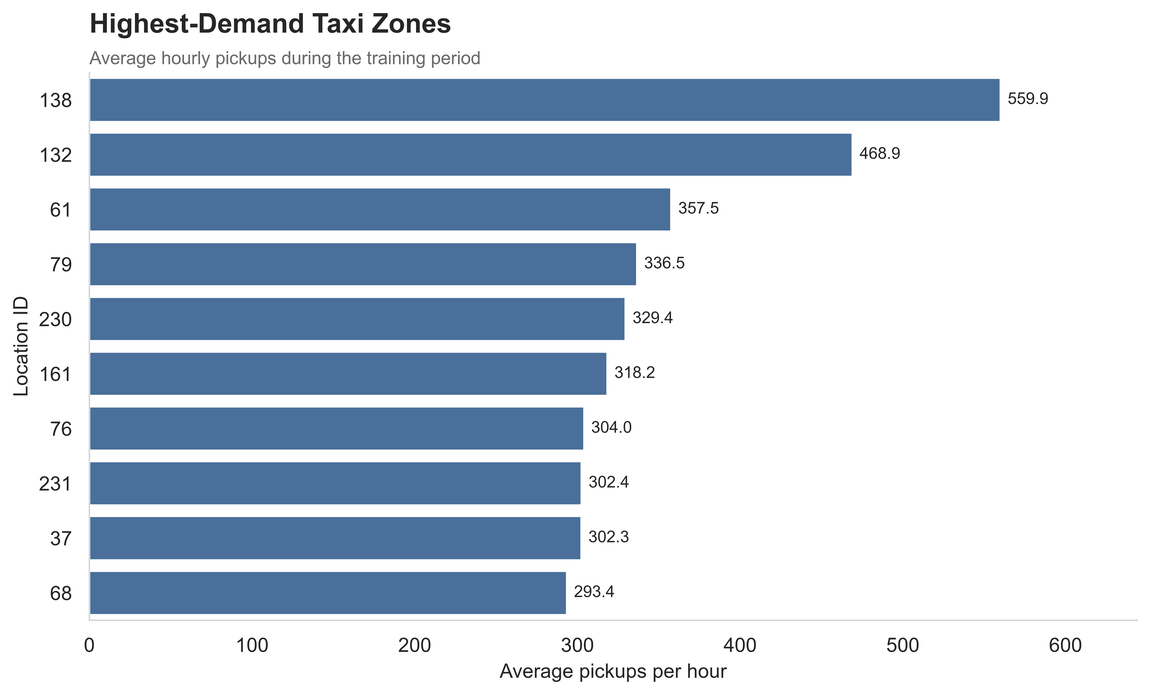

,location_id,Borough,Zone,mean_pickups
0,138,Queens,LaGuardia Airport,559.940
1,132,Queens,JFK Airport,468.940
2,61,Brooklyn,Crown Heights North,357.490
3,79,Manhattan,East Village,336.490
4,230,Manhattan,Times Sq/Theatre District,329.390
5,161,Manhattan,Midtown Center,318.250
6,76,Brooklyn,East New York,303.980
7,231,Manhattan,TriBeCa/Civic Center,302.380
8,37,Brooklyn,Bushwick South,302.260
9,68,Manhattan,East Chelsea,293.390


In [ ]:
# Selecting the ten highest-demand zones
top_demand_zones = (
    zone_zero_rates
    .nlargest(10, "mean_pickups")
    .sort_values("mean_pickups", ascending=False)
)

# Visualizing average demand by zone
fig, ax = plt.subplots(figsize=(9, 5.5))

sns.barplot(
    data=top_demand_zones,
    x="mean_pickups",
    y=top_demand_zones["location_id"].astype(str),
    color="#3B6EA8",
    ax=ax,
)

ax.bar_label(
    ax.containers[0],
    fmt="%.1f",
    padding=4,
    fontsize=9,
)

ax.set_title(
    "Highest-Demand Taxi Zones",
    loc="left",
    fontsize=15,
    fontweight="bold",
    pad=22,
)

ax.text(
    0,
    1.015,
    "Average hourly pickups during the training period",
    transform=ax.transAxes,
    fontsize=10,
    color="dimgray",
    ha="left",
)

ax.set(
    xlabel="Average pickups per hour",
    ylabel="Location ID",
)

ax.set_xlim(0, top_demand_zones["mean_pickups"].max() * 1.15)

sns.despine()
plt.tight_layout()
plt.show()

# Loading the NYC taxi-zone names
taxi_zone_lookup = pd.read_csv(
    PROJECT_ROOT / "data" / "external" / "taxi_zone_lookup.csv"
)

# Adding readable zone information
top_demand_zones_named = top_demand_zones.merge(
    taxi_zone_lookup[
        ["LocationID", "Borough", "Zone"]
    ],
    left_on="location_id",
    right_on="LocationID",
    how="left",
)

display(
    top_demand_zones_named[
        ["location_id", "Borough", "Zone", "mean_pickups"]
    ].sort_values("mean_pickups", ascending=False)
)

### What does a citywide average hide?

The busiest zones are far above the average. Zone 138 has about 560 pickups an hour and zone 132 about 469, compared with roughly 105 across zone-hours overall. This is why a 50-pickup miss has a different practical meaning depending on the location.


In [ ]:
# Calculating average demand by local hour
hourly_demand = duckdb_connection.execute("""
    SELECT
        hour_of_day,
        ROUND(AVG(total_pickups), 2) AS mean_pickups,
        MEDIAN(total_pickups) AS median_pickups
    FROM training_demand
    GROUP BY hour_of_day
    ORDER BY hour_of_day
""").df()

display(hourly_demand)

,hour_of_day,mean_pickups,median_pickups
0,0,91.130,49.000
1,1,63.820,30.000
2,2,45.900,21.000
3,3,37.050,19.000
4,4,39.050,27.000
5,5,45.930,38.000
6,6,70.680,60.000
7,7,105.260,87.000
8,8,127.730,108.000
9,9,119.140,101.000


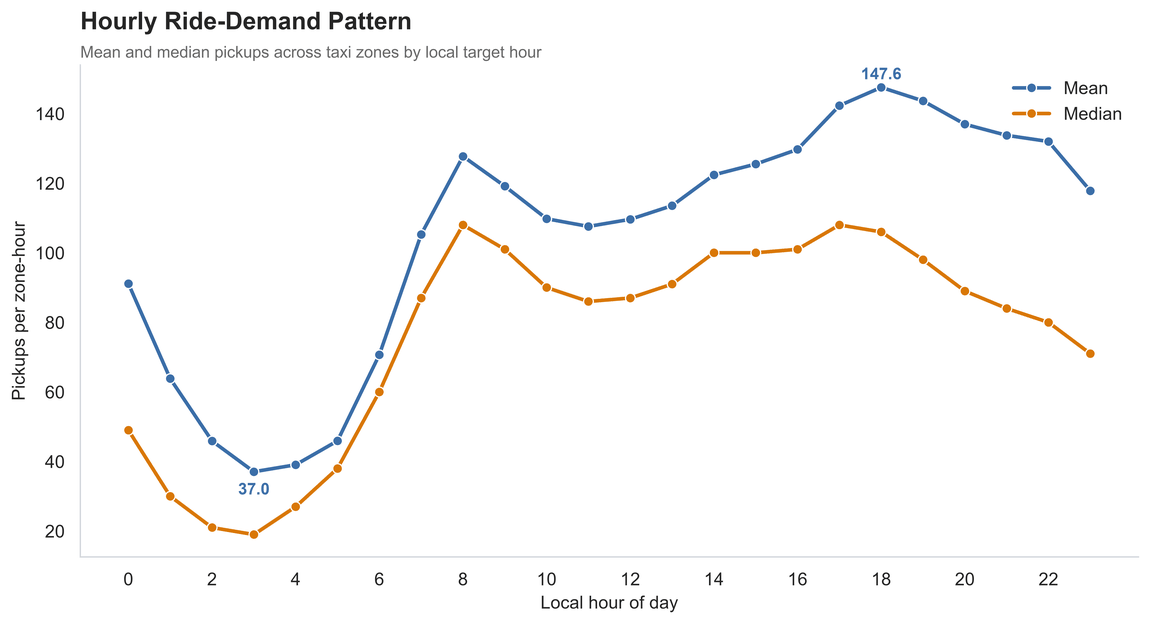

In [ ]:
# Reshaping the hourly summary for Seaborn
hourly_demand_long = hourly_demand.melt(
    id_vars="hour_of_day",
    value_vars=["mean_pickups", "median_pickups"],
    var_name="measure",
    value_name="pickups",
)

hourly_demand_long["measure"] = hourly_demand_long["measure"].map({
    "mean_pickups": "Mean",
    "median_pickups": "Median",
})

# Visualizing the hourly demand cycle
fig, ax = plt.subplots(figsize=(10, 5.5))

sns.lineplot(
    data=hourly_demand_long,
    x="hour_of_day",
    y="pickups",
    hue="measure",
    marker="o",
    linewidth=2.2,
    palette={
        "Mean": "#3B6EA8",
        "Median": "#D97706",
    },
    ax=ax,
)

# Identifying the lowest and highest hourly averages
lowest_mean = hourly_demand.loc[
    hourly_demand["mean_pickups"].idxmin()
]

highest_mean = hourly_demand.loc[
    hourly_demand["mean_pickups"].idxmax()
]

# Labeling the lowest average
ax.annotate(
    f'{lowest_mean["mean_pickups"]:.1f}',
    xy=(
        lowest_mean["hour_of_day"],
        lowest_mean["mean_pickups"],
    ),
    xytext=(0, -14),
    textcoords="offset points",
    ha="center",
    fontsize=10,
    fontweight="bold",
    color="#3B6EA8",
)

# Labeling the highest average
ax.annotate(
    f'{highest_mean["mean_pickups"]:.1f}',
    xy=(
        highest_mean["hour_of_day"],
        highest_mean["mean_pickups"],
    ),
    xytext=(0, 5),
    textcoords="offset points",
    ha="center",
    fontsize=10,
    fontweight="bold",
    color="#3B6EA8",
)

ax.set_title(
    "Hourly Ride-Demand Pattern",
    loc="left",
    fontsize=15,
    fontweight="bold",
    pad=22,
)

ax.text(
    0,
    1.015,
    "Mean and median pickups across taxi zones by local target hour",
    transform=ax.transAxes,
    fontsize=10,
    color="dimgray",
    ha="left",
)

ax.set(
    xlabel="Local hour of day",
    ylabel="Pickups per zone-hour",
    xticks=range(0, 24, 2),
)

ax.legend(title=None)
sns.despine()
plt.tight_layout()
plt.show()

### When does the city get busy again?

The daily curve falls to its low point around 3 AM, then rises quickly through the morning. There is another strong evening peak. Hour of day clearly belongs in the candidate features, but I also want to know whether weekdays and weekends follow that same shape.


In [ ]:
# Comparing weekday and weekend hourly demand
day_type_hourly_demand = duckdb_connection.execute("""
    SELECT
        CASE
            WHEN is_weekend THEN 'Weekend'
            ELSE 'Weekday'
        END AS day_type,
        hour_of_day,
        ROUND(AVG(total_pickups), 2) AS mean_pickups
    FROM training_demand
    GROUP BY
        day_type,
        hour_of_day
    ORDER BY
        day_type,
        hour_of_day
""").df()

#display(day_type_hourly_demand)

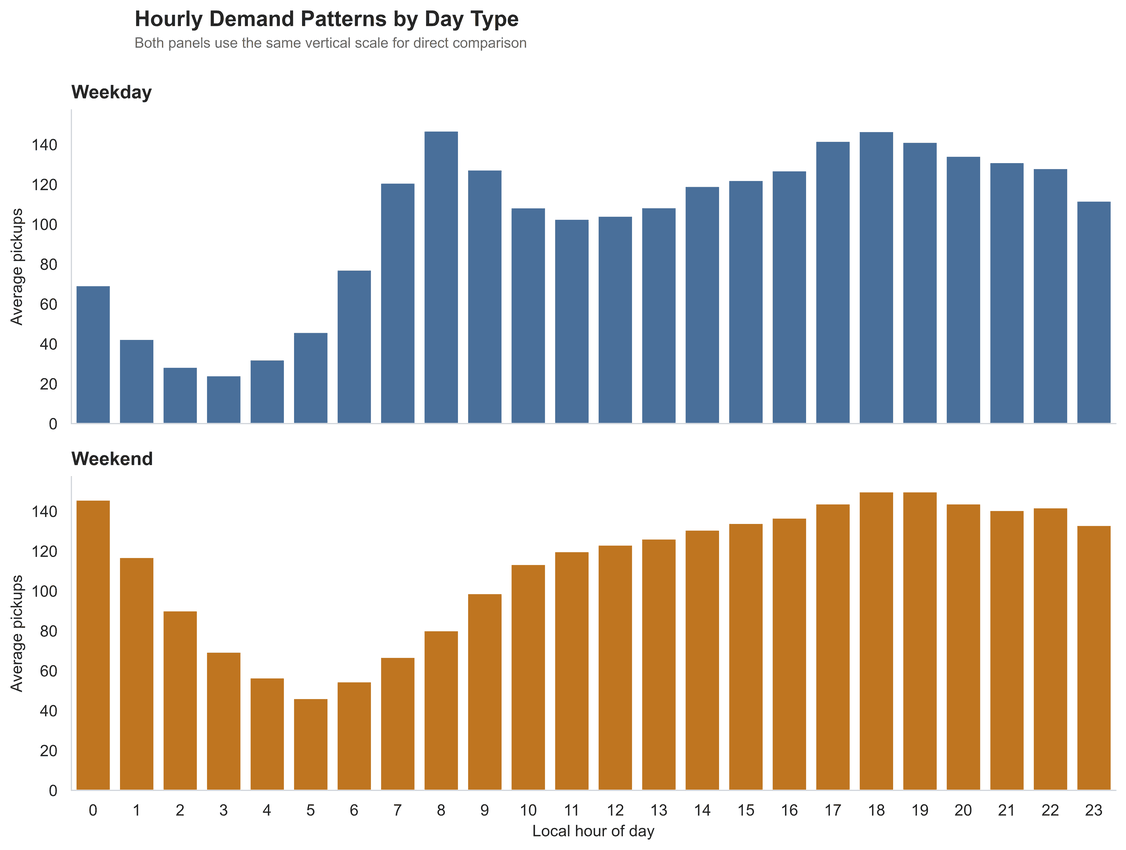

In [ ]:
# Creating vertically stacked hourly bar charts
fig, axes = plt.subplots(
    2,
    1,
    figsize=(11, 8),
    sharex=True,
    sharey=True,
)

day_type_colors = {
    "Weekday": "#3B6EA8",
    "Weekend": "#D97706",
}

for ax, day_type in zip(axes, ["Weekday", "Weekend"]):
    plot_data = day_type_hourly_demand[
        day_type_hourly_demand["day_type"] == day_type
    ]

    sns.barplot(
        data=plot_data,
        x="hour_of_day",
        y="mean_pickups",
        color=day_type_colors[day_type],
        ax=ax,
    )

    ax.set_title(
        day_type,
        loc="left",
        fontsize=13,
        fontweight="bold",
        pad=8,
    )

    ax.set(
        xlabel=None,
        ylabel="Average pickups",
    )

axes[1].set_xlabel("Local hour of day")

fig.suptitle(
    "Hourly Demand Patterns by Day Type",
    x=0.125,
    ha="left",
    fontsize=15,
    fontweight="bold",
    y=1.02,
)

fig.text(
    0.125,
    0.975,
    "Both panels use the same vertical scale for direct comparison",
    fontsize=10,
    color="dimgray",
    ha="left",
)

sns.despine()
plt.tight_layout()
plt.show()

### Does Saturday look like Monday?

They do not. Weekdays have a sharper morning commute pattern, while weekends retain more late-night activity and build differently through the day. The model needs to distinguish those combinations rather than learn one average curve for every day.


In [ ]:
# Calculating monthly hourly demand patterns
month_hour_demand = duckdb_connection.execute("""
    SELECT
        month,
        hour_of_day,
        ROUND(AVG(total_pickups), 2) AS mean_pickups
    FROM training_demand
    GROUP BY
        month,
        hour_of_day
    ORDER BY
        month,
        hour_of_day
""").df()

print("Month-hour combinations:", len(month_hour_demand))
display(month_hour_demand.head())

Month-hour combinations: 288


,month,hour_of_day,mean_pickups
0,1,0,83.700
1,1,1,58.580
2,1,2,43.260
3,1,3,35.490
4,1,4,36.800


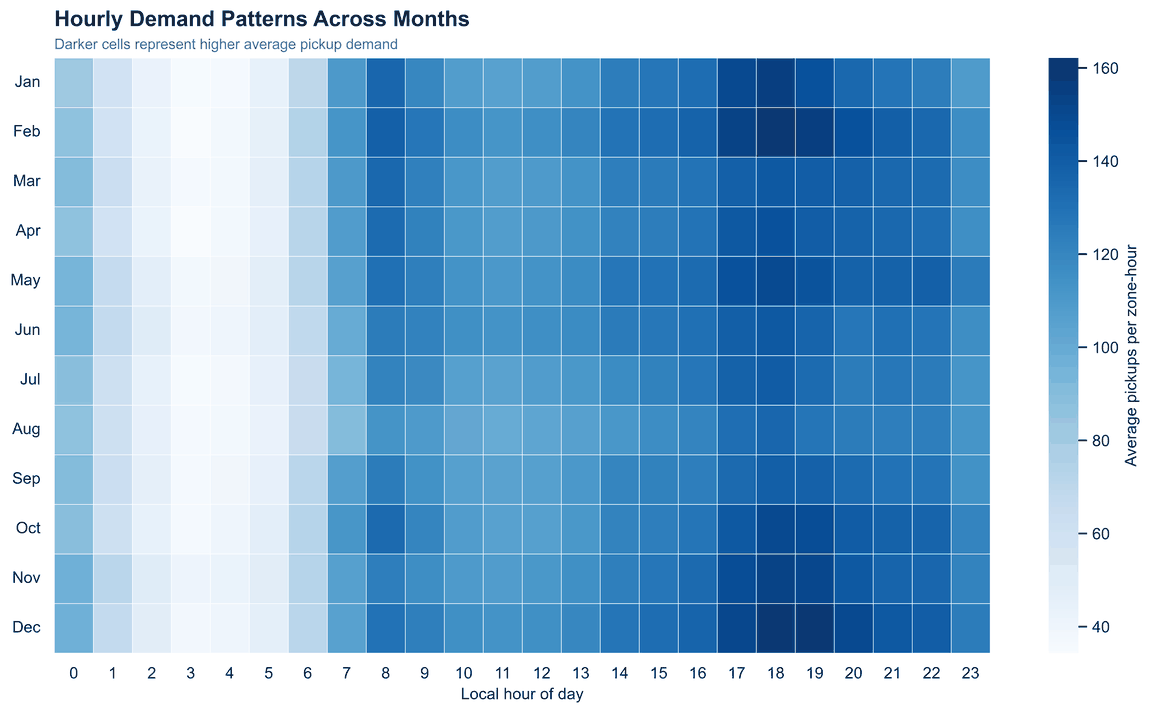

In [ ]:
# Reshaping the monthly hourly averages
month_hour_matrix = month_hour_demand.pivot(
    index="month",
    columns="hour_of_day",
    values="mean_pickups",
)

month_labels = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec",
]

# Visualizing seasonal changes in the daily demand cycle
fig, ax = plt.subplots(figsize=(12, 7))

sns.heatmap(
    month_hour_matrix,
    cmap="Blues",
    linewidths=0.3,
    linecolor="white",
    cbar_kws={
        "label": "Average pickups per zone-hour",
    },
    ax=ax,
)

ax.set_title(
    "Hourly Demand Patterns Across Months",
    loc="left",
    fontsize=15,
    fontweight="bold",
    pad=22,
)

ax.text(
    0,
    1.015,
    "Darker cells represent higher average pickup demand",
    transform=ax.transAxes,
    fontsize=10,
    color="dimgray",
    ha="left",
)

ax.set(
    xlabel="Local hour of day",
    ylabel=None,
    yticklabels=month_labels,
)

ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

### Do the same peaks show up every month?

The broad daily rhythm appears across months, but the levels and peaks vary. I'll keep month and hour as potentially useful inputs without assuming their averages capture every seasonal change.


## 4. When does last week stop being a good guide?

Now I'll look for hours that are unusual for their own zone. A citywide cutoff would miss a big surge in a quiet place and might label ordinary airport activity as an outlier. I also want to see whether the historical lags keep up during those hours.


In [ ]:
# Extending the demand view for extreme and lag analysis
duckdb_connection.execute("""
    CREATE OR REPLACE VIEW training_demand AS

    SELECT
        target_hour_utc,
        target_hour_local,
        location_id,
        total_pickups,
        pickup_lag_24,
        pickup_lag_168,
        pickup_lag_336,
        hour_of_day,
        day_of_week,
        month,
        is_weekend,
        is_holiday,
        is_unofficial_holiday,
        is_post_game_demand,
        is_concert_window,
        is_wide_concert_window

    FROM training_forecast_rows

    QUALIFY ROW_NUMBER() OVER (
        PARTITION BY target_hour_utc, location_id
        ORDER BY forecast_horizon
    ) = 1
""")

In [ ]:
# Finding demand above each zone's 99.9th percentile
zone_relative_extremes = duckdb_connection.execute("""
    WITH zone_thresholds AS (
        SELECT
            location_id,
            QUANTILE_CONT(
                total_pickups,
                0.999
            ) AS zone_p999
        FROM training_demand
        GROUP BY location_id
    )

    SELECT
        d.target_hour_local,
        d.location_id,
        d.total_pickups,
        ROUND(t.zone_p999, 1) AS zone_p999,
        ROUND(
            d.total_pickups / NULLIF(t.zone_p999, 0),
            2
        ) AS multiple_of_p999,
        d.pickup_lag_24,
        d.pickup_lag_168,
        d.pickup_lag_336
    FROM training_demand AS d
    INNER JOIN zone_thresholds AS t
        ON d.location_id = t.location_id
    WHERE
        t.zone_p999 > 0
        AND d.total_pickups > t.zone_p999
    ORDER BY
        multiple_of_p999 DESC,
        d.total_pickups DESC
    LIMIT 20
""").df()

# Adding readable geographic labels
zone_relative_extremes = zone_relative_extremes.merge(
    taxi_zone_lookup[
        ["LocationID", "Borough", "Zone"]
    ],
    left_on="location_id",
    right_on="LocationID",
    how="left",
)

# Preparing a cleaner extreme-record table
extreme_display = (
    zone_relative_extremes
    .assign(
        area=lambda data: (
            data["Zone"]
            + " ("
            + data["Borough"]
            + ")"
        ),
        target_hour_local=lambda data: (
            data["target_hour_local"]
            .dt.strftime("%Y-%m-%d %H:%M")
        ),
    )
    .rename(columns={
        "target_hour_local": "Local target hour",
        "location_id": "Location ID",
        "area": "Zone and borough",
        "total_pickups": "Pickups",
        "zone_p999": "Zone 99.9%",
        "multiple_of_p999": "Multiple",
        "pickup_lag_24": "Lag 24h",
        "pickup_lag_168": "Lag 168h",
        "pickup_lag_336": "Lag 336h",
    })
    [
        [
            "Local target hour",
            "Location ID",
            "Zone and borough",
            "Pickups",
            "Zone 99.9%",
            "Multiple",
            "Lag 24h",
            "Lag 168h",
            "Lag 336h",
        ]
    ]
)

# Styling the unusual-record table
display(
    extreme_display.style
    .hide(axis="index")
    .set_caption(
        "Largest Zone-Relative Demand Extremes"
    )
    .format({
        "Pickups": "{:,.0f}",
        "Zone 99.9%": "{:,.1f}",
        "Multiple": "{:.2f}×",
        "Lag 24h": "{:,.0f}",
        "Lag 168h": "{:,.0f}",
        "Lag 336h": "{:,.0f}",
    })
    .background_gradient(
        subset=["Pickups"],
        cmap="Blues",
    )
    .background_gradient(
        subset=["Multiple"],
        cmap="Oranges",
    )
    .set_properties(
        subset=["Zone and borough"],
        **{"text-align": "left"},
    )
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("font-size", "16px"),
                ("font-weight", "bold"),
                ("text-align", "left"),
                ("padding-bottom", "10px"),
            ],
        },
        {
            "selector": "th",
            "props": [
                ("text-align", "left"),
                ("background-color", "#F3F4F6"),
            ],
        },
    ])
)

Local target hour,Location ID,Zone and borough,Pickups,Zone 99.9%,Multiple,Lag 24h,Lag 168h,Lag 336h
2025-08-02 21:00,59,Crotona Park (Bronx),112,31.0,3.61×,45,35,24
2025-05-24 23:00,195,Red Hook (Brooklyn),834,239.0,3.49×,170,151,177
2025-05-23 22:00,195,Red Hook (Brooklyn),827,239.0,3.46×,67,100,111
2025-06-13 21:00,110,Great Kills Park (Staten Island),6,2.0,3.00×,0,1,0
2025-08-07 23:00,184,Pelham Bay Park (Bronx),174,66.0,2.64×,32,3,8
2025-03-02 16:00,245,West Brighton (Staten Island),232,89.3,2.60×,37,15,23
2025-03-02 18:00,245,West Brighton (Staten Island),224,89.3,2.51×,39,15,24
2024-10-10 13:00,8,Astoria Park (Queens),36,14.8,2.43×,1,1,0
2024-10-18 22:00,111,Green-Wood Cemetery (Brooklyn),42,17.4,2.42×,26,1,1
2025-10-16 22:00,111,Green-Wood Cemetery (Brooklyn),42,17.4,2.42×,1,0,5


### What counts as an unusual hour for this zone?

I use each zone's 99.9th percentile as a way to choose records for inspection. In very quiet zones, even a small count can cross that threshold, so I also distinguish cases with at least 100 pickups. This is a review tool, not a rule for deleting rows.

$$
\text{upper fence}
 =

Q_3 + 1.5(Q_3-Q_1)
$$


In [ ]:
# Comparing event coverage among zone-relative extremes
extreme_event_summary = duckdb_connection.execute("""
    WITH zone_thresholds AS (
        SELECT
            location_id,
            QUANTILE_CONT(
                total_pickups,
                0.999
            ) AS zone_p999
        FROM training_demand
        GROUP BY location_id
    ),

    relative_extremes AS (
        SELECT
            d.*,
            CASE
                WHEN d.total_pickups >= 100
                    THEN 'At least 100 pickups'
                ELSE 'Below 100 pickups'
            END AS absolute_scale
        FROM training_demand AS d
        INNER JOIN zone_thresholds AS t
            ON d.location_id = t.location_id
        WHERE
            t.zone_p999 > 0
            AND d.total_pickups > t.zone_p999
    )

    SELECT
        absolute_scale,
        COUNT(*) AS extreme_records,
        COUNT(*) FILTER (
            WHERE is_holiday
        ) AS official_holiday,
        COUNT(*) FILTER (
            WHERE is_unofficial_holiday
        ) AS unofficial_holiday,
        COUNT(*) FILTER (
            WHERE is_post_game_demand
        ) AS post_game,
        COUNT(*) FILTER (
            WHERE is_concert_window
        ) AS concert_window,
        COUNT(*) FILTER (
            WHERE is_wide_concert_window
        ) AS wide_concert_window,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE
                    is_holiday
                    OR is_unofficial_holiday
                    OR is_post_game_demand
                    OR is_concert_window
                    OR is_wide_concert_window
            ) / COUNT(*),
            2
        ) AS any_event_flag_percent
    FROM relative_extremes
    GROUP BY absolute_scale
    ORDER BY absolute_scale
""").df()

display(extreme_event_summary)

,absolute_scale,extreme_records,official_holiday,unofficial_holiday,post_game,concert_window,wide_concert_window,any_event_flag_percent
0,At least 100 pickups,2677,383,473,5,39,51,31.450
1,Below 100 pickups,546,46,67,0,0,0,17.770


### How many busy extremes line up with an event?

About 31% of the substantial extremes coincide with an available holiday or event flag. That is useful coverage, but it leaves most extremes unexplained by these indicators. I'll compare their frequency with ordinary hours before deciding how much this association tells me.


In [ ]:
# Comparing event rates for extreme and non-extreme demand
event_rate_comparison = duckdb_connection.execute("""
    WITH zone_thresholds AS (
        SELECT
            location_id,
            QUANTILE_CONT(
                total_pickups,
                0.999
            ) AS zone_p999
        FROM training_demand
        GROUP BY location_id
    ),

    labeled_demand AS (
        SELECT
            d.*,
            d.total_pickups > t.zone_p999
                AS is_zone_extreme
        FROM training_demand AS d
        INNER JOIN zone_thresholds AS t
            ON d.location_id = t.location_id
        WHERE
            t.zone_p999 > 0
            AND d.total_pickups >= 100
    )

    SELECT
        CASE
            WHEN is_zone_extreme
                THEN 'Zone-relative extreme'
            ELSE 'Other observations'
        END AS demand_group,
        COUNT(*) AS records,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE
                    is_holiday
                    OR is_unofficial_holiday
                    OR is_post_game_demand
                    OR is_concert_window
                    OR is_wide_concert_window
            ) / COUNT(*),
            2
        ) AS any_event_flag_percent,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE is_holiday
            ) / COUNT(*),
            2
        ) AS official_holiday_percent,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE is_unofficial_holiday
            ) / COUNT(*),
            2
        ) AS unofficial_holiday_percent,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE
                    is_post_game_demand
                    OR is_concert_window
                    OR is_wide_concert_window
            ) / COUNT(*),
            2
        ) AS game_or_concert_percent
    FROM labeled_demand
    GROUP BY is_zone_extreme
    ORDER BY is_zone_extreme DESC
""").df()

display(event_rate_comparison)

,demand_group,records,any_event_flag_percent,official_holiday_percent,unofficial_holiday_percent,game_or_concert_percent
0,Zone-relative extreme,2677,31.450,14.310,17.670,2.090
1,Other observations,1218882,4.720,3.480,1.210,0.210


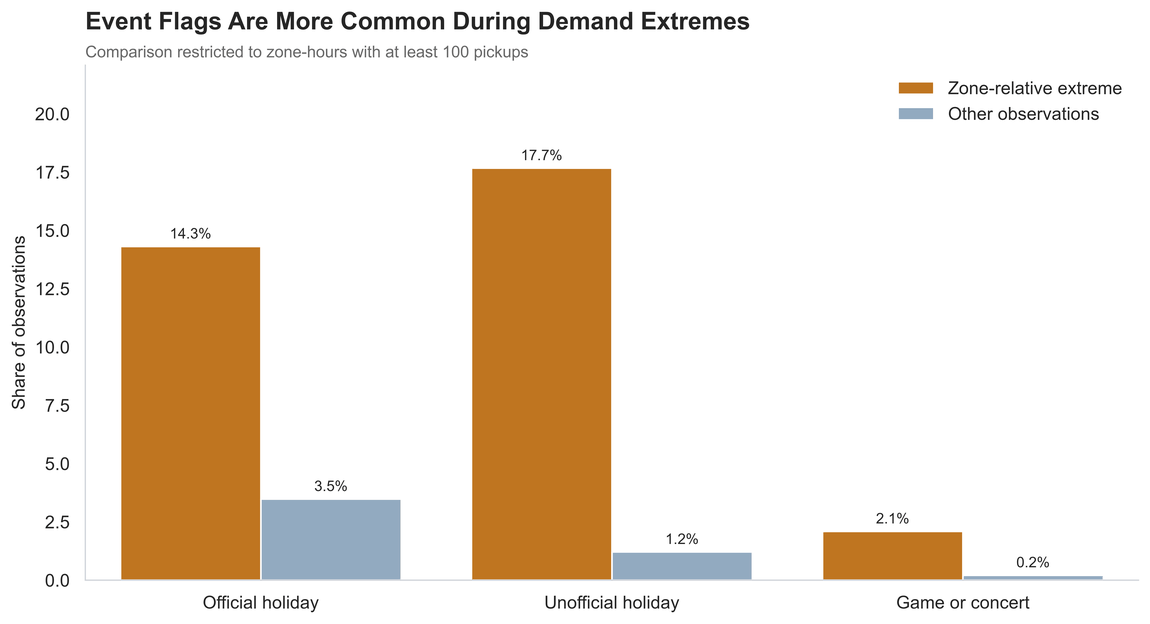

In [ ]:
# Reshaping event rates for comparison
event_rate_plot = event_rate_comparison.melt(
    id_vars="demand_group",
    value_vars=[
        "official_holiday_percent",
        "unofficial_holiday_percent",
        "game_or_concert_percent",
    ],
    var_name="event_type",
    value_name="percent",
)

event_rate_plot["event_type"] = event_rate_plot["event_type"].map({
    "official_holiday_percent": "Official holiday",
    "unofficial_holiday_percent": "Unofficial holiday",
    "game_or_concert_percent": "Game or concert",
})

# Visualizing event-flag enrichment
fig, ax = plt.subplots(figsize=(10, 5.5))

sns.barplot(
    data=event_rate_plot,
    x="event_type",
    y="percent",
    hue="demand_group",
    palette={
        "Zone-relative extreme": "#D97706",
        "Other observations": "#8AAAC8",
    },
    ax=ax,
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3,
        fontsize=9,
    )

ax.set_title(
    "Event Flags Are More Common During Demand Extremes",
    loc="left",
    fontsize=15,
    fontweight="bold",
    pad=22,
)

ax.text(
    0,
    1.015,
    "Comparison restricted to zone-hours with at least 100 pickups",
    transform=ax.transAxes,
    fontsize=10,
    color="dimgray",
    ha="left",
)

ax.set(
    xlabel=None,
    ylabel="Share of observations",
)

ax.set_ylim(
    0,
    event_rate_plot["percent"].max() * 1.25,
)

ax.legend(title=None)
sns.despine()
plt.tight_layout()
plt.show()

### Are event flags more common in the busiest hours?

The flags are more common among substantial extremes than among other busy observations. That gives me a reason to test them in the model. It does not yet tell me whether they add information beyond the pickup lags and calendar fields already available.


In [ ]:
# Comparing realized demand with each lag feature
lag_comparison = duckdb_connection.execute("""
    SELECT
        24 AS lag_hours,
        COUNT(pickup_lag_24) AS available_records,
        ROUND(
            CORR(total_pickups, pickup_lag_24),
            3
        ) AS correlation,
        ROUND(
            AVG(ABS(total_pickups - pickup_lag_24)),
            2
        ) AS mean_absolute_difference,
        ROUND(
            AVG(total_pickups - pickup_lag_24),
            2
        ) AS mean_signed_difference
    FROM training_demand

    UNION ALL

    SELECT
        168,
        COUNT(pickup_lag_168),
        ROUND(
            CORR(total_pickups, pickup_lag_168),
            3
        ),
        ROUND(
            AVG(ABS(total_pickups - pickup_lag_168)),
            2
        ),
        ROUND(
            AVG(total_pickups - pickup_lag_168),
            2
        )
    FROM training_demand

    UNION ALL

    SELECT
        336,
        COUNT(pickup_lag_336),
        ROUND(
            CORR(total_pickups, pickup_lag_336),
            3
        ),
        ROUND(
            AVG(ABS(total_pickups - pickup_lag_336)),
            2
        ),
        ROUND(
            AVG(total_pickups - pickup_lag_336),
            2
        )
    FROM training_demand

    ORDER BY lag_hours
""").df()

display(lag_comparison)

,lag_hours,available_records,correlation,mean_absolute_difference,mean_signed_difference
0,24,3212019,0.894,25.260,0.020
1,168,3212019,0.944,18.380,-0.110
2,336,3212019,0.935,19.570,0.070


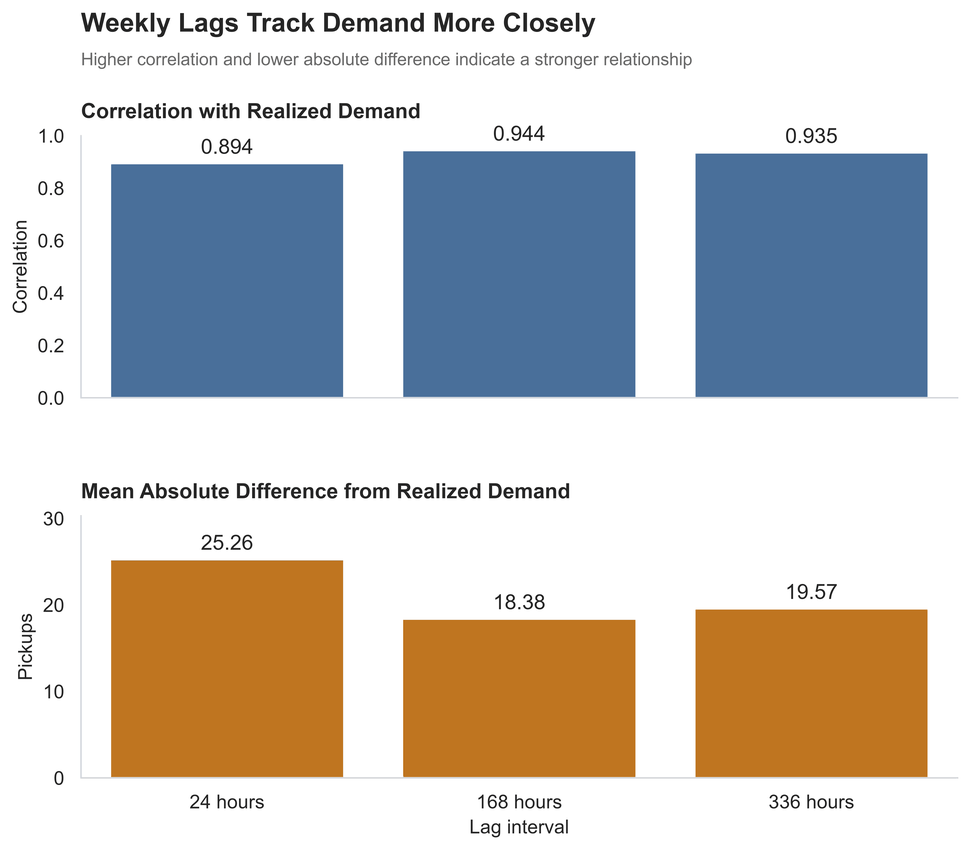

In [ ]:
# Creating readable lag labels
lag_comparison["lag_label"] = (
    lag_comparison["lag_hours"].astype(str)
    + " hours"
)

# Creating two separated comparison panels
fig, axes = plt.subplots(
    2,
    1,
    figsize=(9, 7),
    sharex=True,
)

# Plotting correlations
sns.barplot(
    data=lag_comparison,
    x="lag_label",
    y="correlation",
    color="#3B6EA8",
    ax=axes[0],
)

axes[0].bar_label(
    axes[0].containers[0],
    fmt="%.3f",
    padding=3,
)

axes[0].set_title(
    "Correlation with Realized Demand",
    loc="left",
    fontsize=12,
    fontweight="bold",
    pad=10,
)

axes[0].set(
    xlabel=None,
    ylabel="Correlation",
    ylim=(0, 1),
)

# Plotting absolute differences
sns.barplot(
    data=lag_comparison,
    x="lag_label",
    y="mean_absolute_difference",
    color="#D97706",
    ax=axes[1],
)

axes[1].bar_label(
    axes[1].containers[0],
    fmt="%.2f",
    padding=3,
)

axes[1].set_title(
    "Mean Absolute Difference from Realized Demand",
    loc="left",
    fontsize=12,
    fontweight="bold",
    pad=10,
)

axes[1].set(
    xlabel="Lag interval",
    ylabel="Pickups",
    ylim=(
        0,
        lag_comparison[
            "mean_absolute_difference"
        ].max() * 1.2,
    ),
)

# Adding the shared title and subtitle
fig.suptitle(
    "Weekly Lags Track Demand More Closely",
    x=0.125,
    ha="left",
    fontsize=15,
    fontweight="bold",
    y=0.98,
)

fig.text(
    0.125,
    0.92,
    "Higher correlation and lower absolute difference indicate a stronger relationship",
    fontsize=10,
    color="dimgray",
    ha="left",
)

sns.despine()

fig.subplots_adjust(
    top=0.84,
    hspace=0.45,
)

plt.show()

### How close are the historical lags?

My first benchmark is simple. For a Tuesday at 8 a.m., I use the pickups in that same zone last Tuesday at 8 a.m. A more complicated model has to earn its place by improving on that comparison.

The same hour last week is the closest historical match: correlation is 0.944 and its mean absolute difference is about 18.4 pickups. The two-week lag is close, while yesterday is weaker. That fits the idea that a Monday morning resembles another Monday more than a Sunday. I'll now see whether that relationship holds during unusual activity.


In [ ]:
# Comparing lag behavior during substantial demand extremes
extreme_lag_comparison = duckdb_connection.execute("""
    WITH zone_thresholds AS (
        SELECT
            location_id,
            QUANTILE_CONT(
                total_pickups,
                0.999
            ) AS zone_p999
        FROM training_demand
        GROUP BY location_id
    ),

    labeled_demand AS (
        SELECT
            d.*,
            d.total_pickups > t.zone_p999
                AS is_zone_extreme
        FROM training_demand AS d
        INNER JOIN zone_thresholds AS t
            ON d.location_id = t.location_id
        WHERE
            t.zone_p999 > 0
            AND d.total_pickups >= 100
    )

    SELECT
        CASE
            WHEN is_zone_extreme
                THEN 'Zone-relative extreme'
            ELSE 'Other observations'
        END AS demand_group,
        COUNT(*) AS records,
        ROUND(
            AVG(ABS(total_pickups - pickup_lag_24)),
            2
        ) AS lag_24_absolute_difference,
        ROUND(
            AVG(ABS(total_pickups - pickup_lag_168)),
            2
        ) AS lag_168_absolute_difference,
        ROUND(
            AVG(ABS(total_pickups - pickup_lag_336)),
            2
        ) AS lag_336_absolute_difference
    FROM labeled_demand
    GROUP BY is_zone_extreme
    ORDER BY is_zone_extreme DESC
""").df()

display(extreme_lag_comparison)

,demand_group,records,lag_24_absolute_difference,lag_168_absolute_difference,lag_336_absolute_difference
0,Zone-relative extreme,2677,184.530,174.870,199.970
1,Other observations,1218882,45.440,33.560,36.000


### Where the weekly pattern falls short

It weakens considerably. For substantial extremes, the weekly lag's average absolute difference rises from about 34 to 175 pickups. Part of that may simply come from larger outcomes, so I'll normalize by total pickups before deciding that the lag has become less reliable in relative terms too.


In [ ]:
# Comparing normalized lag differences
extreme_lag_wape = duckdb_connection.execute("""
    WITH zone_thresholds AS (
        SELECT
            location_id,
            QUANTILE_CONT(
                total_pickups,
                0.999
            ) AS zone_p999
        FROM training_demand
        GROUP BY location_id
    ),

    labeled_demand AS (
        SELECT
            d.*,
            d.total_pickups > t.zone_p999
                AS is_zone_extreme
        FROM training_demand AS d
        INNER JOIN zone_thresholds AS t
            ON d.location_id = t.location_id
        WHERE
            t.zone_p999 > 0
            AND d.total_pickups >= 100
    )

    SELECT
        CASE
            WHEN is_zone_extreme
                THEN 'Zone-relative extreme'
            ELSE 'Other observations'
        END AS demand_group,
        ROUND(
            100.0
            * SUM(ABS(total_pickups - pickup_lag_24))
            / SUM(total_pickups),
            2
        ) AS lag_24_wape_percent,
        ROUND(
            100.0
            * SUM(ABS(total_pickups - pickup_lag_168))
            / SUM(total_pickups),
            2
        ) AS lag_168_wape_percent,
        ROUND(
            100.0
            * SUM(ABS(total_pickups - pickup_lag_336))
            / SUM(total_pickups),
            2
        ) AS lag_336_wape_percent
    FROM labeled_demand
    GROUP BY is_zone_extreme
    ORDER BY is_zone_extreme DESC
""").df()

display(extreme_lag_wape)

,demand_group,lag_24_wape_percent,lag_168_wape_percent,lag_336_wape_percent
0,Zone-relative extreme,43.330,41.070,46.960
1,Other observations,21.460,15.850,17.000


### Is the weekly error larger even after accounting for volume?

Weekly-lag WAPE also rises, from about 15.9% to 41.1%. So this is not only a matter of counting errors against larger volumes. I'll keep the lags as strong everyday references, but unusual surges give the model something important to improve upon.


## 5. What happens when forecast weather is missing?

For weather, I need to return to forecast rows. Two predictions for the same target can use different selected runs, so collapsing them would lose part of the input story. These are archived forecasts selected under the seven-hour policy; the remaining provenance and publication-time questions belong alongside that design.


In [ ]:
# Summarizing forecast-weather distributions
weather_summary = duckdb_connection.execute("""
    SUMMARIZE
    SELECT
        forecast_temperature_f,
        forecast_precipitation_in,
        forecast_rain_in,
        forecast_snowfall_in,
        forecast_wind_speed_mph
    FROM training_forecast_rows
""").df()

# Converting summary values to numeric
weather_numeric_columns = [
    "min",
    "q25",
    "q50",
    "q75",
    "max",
    "avg",
    "std",
    "null_percentage",
]



weather_summary[
    weather_numeric_columns
] = weather_summary[
    weather_numeric_columns
].apply(
    pd.to_numeric,
    errors="coerce",
)

weather_summary =(
    weather_summary
    .rename(index=({'null_percentage' : 'missing_percentage'}))
)
# Rounding the displayed statistics
weather_summary[
    weather_numeric_columns
] = weather_summary[
    weather_numeric_columns
].round(3)

display(
    weather_summary[
        ["column_name"] + weather_numeric_columns
    ]
)



,column_name,min,q25,q50,q75,max,avg,std,null_percentage
0,forecast_temperature_f,1.200,40.090,56.706,69.184,106.400,54.813,18.202,0.440
1,forecast_precipitation_in,0.000,0.000,0.000,0.000,1.051,0.004,0.023,0.690
2,forecast_rain_in,0.000,0.000,0.000,0.000,1.008,0.002,0.012,0.880
3,forecast_snowfall_in,0.000,0.000,0.000,0.000,1.791,0.002,0.025,0.390
4,forecast_wind_speed_mph,0.000,4.117,6.142,8.615,30.900,6.627,3.466,0.740


### Do the weather values look plausible?

The ranges look broadly plausible for NYC, though the extremes need inspection. I want to distinguish an unusual forecast from a broken value before applying a cap that could erase a real weather condition.


In [ ]:
# Calculating weather missingness by forecast horizon
weather_missingness_by_horizon = duckdb_connection.execute("""
    SELECT
        forecast_horizon,
        COUNT(*) AS forecast_rows,
        ROUND(
            100.0 * AVG(
                CASE
                    WHEN forecast_temperature_f IS NULL
                        THEN 1
                    ELSE 0
                END
            ),
            3
        ) AS temperature_missing_percent,
        ROUND(
            100.0 * AVG(
                CASE
                    WHEN forecast_precipitation_in IS NULL
                        THEN 1
                    ELSE 0
                END
            ),
            3
        ) AS precipitation_missing_percent,
        ROUND(
            100.0 * AVG(
                CASE
                    WHEN forecast_rain_in IS NULL
                        THEN 1
                    ELSE 0
                END
            ),
            3
        ) AS rain_missing_percent,
        ROUND(
            100.0 * AVG(
                CASE
                    WHEN forecast_snowfall_in IS NULL
                        THEN 1
                    ELSE 0
                END
            ),
            3
        ) AS snowfall_missing_percent,
        ROUND(
            100.0 * AVG(
                CASE
                    WHEN forecast_wind_speed_mph IS NULL
                        THEN 1
                    ELSE 0
                END
            ),
            3
        ) AS wind_missing_percent
    FROM training_forecast_rows
    GROUP BY forecast_horizon
    ORDER BY forecast_horizon
""").df()

display(weather_missingness_by_horizon)

,forecast_horizon,forecast_rows,temperature_missing_percent,precipitation_missing_percent,rain_missing_percent,snowfall_missing_percent,wind_missing_percent
0,1,3210704,0.442,0.688,0.885,0.393,0.737
1,2,3210704,0.442,0.688,0.885,0.393,0.737
2,3,3210704,0.442,0.688,0.885,0.393,0.737
3,4,3210704,0.442,0.688,0.885,0.393,0.737
4,5,3210704,0.442,0.688,0.885,0.393,0.737
5,6,3210704,0.442,0.688,0.885,0.393,0.737


### Are any forecast horizons missing more weather?

The missingness rates are the same across all six pickup horizons. That suggests the gaps are tied to origins or selected runs rather than forecasts becoming incomplete only farther ahead. I'll check when they occur.


In [ ]:
# Calculating weather missingness by forecast-origin month
monthly_weather_missingness = duckdb_connection.execute("""
    SELECT
        STRFTIME(
            forecast_origin_utc,
            '%Y-%m'
        ) AS origin_month,
        COUNT(DISTINCT forecast_origin_utc)
            AS forecast_origins,
        ROUND(
            100.0 * AVG(
                CASE
                    WHEN
                        forecast_temperature_f IS NULL
                        OR forecast_precipitation_in IS NULL
                        OR forecast_rain_in IS NULL
                        OR forecast_snowfall_in IS NULL
                        OR forecast_wind_speed_mph IS NULL
                    THEN 1
                    ELSE 0
                END
            ),
            3
        ) AS any_weather_missing_percent
    FROM training_forecast_rows
    GROUP BY origin_month
    ORDER BY origin_month
""").df()

display(monthly_weather_missingness)

,origin_month,forecast_origins,any_weather_missing_percent
0,2024-08,521,0.000
1,2024-09,720,0.000
2,2024-10,744,0.000
3,2024-11,720,0.000
4,2024-12,744,0.000
5,2025-01,744,0.000
6,2025-02,672,0.000
7,2025-03,744,0.000
8,2025-04,720,0.000
9,2025-05,744,0.000


### A small overall gap hides a concentrated episode

A small percentage can sound like scattered gaps. I checked the dates because losing weather for every zone at once would be a different problem for the forecast.

The training gaps cluster in August 2025. That matters more than the small overall percentage initially suggests: the model may face a continuous stretch of incomplete inputs, not just scattered missing cells. I'll inspect that stretch directly rather than drop it from training.


In [ ]:
# Measuring the scope of the missing-weather episode
missing_weather_scope = duckdb_connection.execute("""
    WITH missing_weather_rows AS (
        SELECT *
        FROM training_forecast_rows
        WHERE
            forecast_temperature_f IS NULL
            OR forecast_precipitation_in IS NULL
            OR forecast_rain_in IS NULL
            OR forecast_snowfall_in IS NULL
            OR forecast_wind_speed_mph IS NULL
    )

    SELECT
        COUNT(*) AS affected_rows,
        COUNT(DISTINCT forecast_origin_utc)
            AS affected_origins,
        COUNT(DISTINCT location_id)
            AS affected_locations,
        COUNT(DISTINCT representative_location_id)
            AS affected_representative_locations,
        COUNT(DISTINCT selected_model_run_utc)
            AS affected_model_runs,
        MIN(forecast_origin_utc)
            AS first_affected_origin_utc,
        MAX(forecast_origin_utc)
            AS last_affected_origin_utc
    FROM missing_weather_rows
""").df()

display(missing_weather_scope)

,affected_rows,affected_origins,affected_locations,affected_representative_locations,affected_model_runs,first_affected_origin_utc,last_affected_origin_utc
0,189360,120,263,28,13,2025-08-04 19:00:00+00:00,2025-08-10 06:00:00+00:00


### How many forecast origins were affected?

The affected rows come from 120 origins between August 4 and 10, across every zone and horizon. That explains the identical horizon rates. The row count is large because each origin expands across geography and six horizons; it is not 189,360 unrelated weather failures.

$$
120 \text{ origins}
\times
263 \text{ zones}
\times
6 \text{ horizons}
=
189{,}360 \text{ rows}
$$


In [ ]:
# Checking weather-value and availability-flag consistency
weather_flag_consistency = duckdb_connection.execute("""
    SELECT
        COUNT(*) FILTER (
            WHERE temperature_forecast_available
                <> (forecast_temperature_f IS NOT NULL)
        ) AS temperature_mismatches,

        COUNT(*) FILTER (
            WHERE precipitation_forecast_available
                <> (forecast_precipitation_in IS NOT NULL)
        ) AS precipitation_mismatches,

        COUNT(*) FILTER (
            WHERE rain_forecast_available
                <> (forecast_rain_in IS NOT NULL)
        ) AS rain_mismatches,

        COUNT(*) FILTER (
            WHERE snowfall_forecast_available
                <> (forecast_snowfall_in IS NOT NULL)
        ) AS snowfall_mismatches,

        COUNT(*) FILTER (
            WHERE wind_forecast_available
                <> (forecast_wind_speed_mph IS NOT NULL)
        ) AS wind_mismatches,

        COUNT(*) FILTER (
            WHERE weather_forecast_has_missing
                <> (
                    forecast_temperature_f IS NULL
                    OR forecast_precipitation_in IS NULL
                    OR forecast_rain_in IS NULL
                    OR forecast_snowfall_in IS NULL
                    OR forecast_wind_speed_mph IS NULL
                )
        ) AS has_missing_flag_mismatches,

        COUNT(*) FILTER (
            WHERE weather_forecast_complete
                <> (
                    forecast_temperature_f IS NOT NULL
                    AND forecast_precipitation_in IS NOT NULL
                    AND forecast_rain_in IS NOT NULL
                    AND forecast_snowfall_in IS NOT NULL
                    AND forecast_wind_speed_mph IS NOT NULL
                )
        ) AS complete_flag_mismatches
    FROM training_forecast_rows
""").df()

display(weather_flag_consistency)

,temperature_mismatches,precipitation_mismatches,rain_mismatches,snowfall_mismatches,wind_mismatches,has_missing_flag_mismatches,complete_flag_mismatches
0,0,0,0,0,0,0,0


### Can I identify the gaps from the saved flags?

The flags agree with the missing values: no mismatches appear in these checks. So a later model or monitor can identify the incomplete inputs from the stored indicators. Next I'll inspect whether the present values are physically consistent.


In [ ]:
# Identifying the most extreme forecast-weather values
extreme_weather_records = duckdb_connection.execute("""
    WITH representative_weather AS (
        SELECT
            forecast_origin_utc,
            target_hour_utc,
            forecast_horizon,
            representative_location_id,
            weather_request_class,
            forecast_temperature_f,
            forecast_precipitation_in,
            forecast_rain_in,
            forecast_snowfall_in,
            forecast_wind_speed_mph
        FROM training_forecast_rows

        QUALIFY ROW_NUMBER() OVER (
            PARTITION BY
                forecast_origin_utc,
                target_hour_utc,
                representative_location_id
            ORDER BY location_id
        ) = 1
    ),

    weather_long AS (
        SELECT
            r.forecast_origin_utc,
            r.target_hour_utc,
            r.forecast_horizon,
            r.representative_location_id,
            r.weather_request_class,
            w.weather_variable,
            w.forecast_value
        FROM representative_weather AS r

        CROSS JOIN LATERAL (
            VALUES
                ('Temperature (°F)', r.forecast_temperature_f),
                ('Precipitation (in)', r.forecast_precipitation_in),
                ('Rain (in)', r.forecast_rain_in),
                ('Snowfall (in)', r.forecast_snowfall_in),
                ('Wind speed (mph)', r.forecast_wind_speed_mph)
        ) AS w(
            weather_variable,
            forecast_value
        )

        WHERE w.forecast_value IS NOT NULL
    ),

    ranked_weather AS (
        SELECT
            *,
            ROW_NUMBER() OVER (
                PARTITION BY weather_variable
                ORDER BY forecast_value DESC
            ) AS maximum_rank,
            ROW_NUMBER() OVER (
                PARTITION BY weather_variable
                ORDER BY forecast_value
            ) AS minimum_rank
        FROM weather_long
    )

    SELECT
        CASE
            WHEN minimum_rank = 1
                THEN 'Minimum'
            ELSE 'Maximum'
        END AS extreme_type,
        weather_variable,
        ROUND(forecast_value, 3) AS forecast_value,
        forecast_origin_utc,
        target_hour_utc,
        forecast_horizon,
        representative_location_id,
        weather_request_class
    FROM ranked_weather
    WHERE
        maximum_rank = 1
        OR (
            weather_variable = 'Temperature (°F)'
            AND minimum_rank = 1
        )
    ORDER BY
        weather_variable,
        extreme_type
""").df()

display(extreme_weather_records)

,extreme_type,weather_variable,forecast_value,forecast_origin_utc,target_hour_utc,forecast_horizon,representative_location_id,weather_request_class
0,Maximum,Precipitation (in),1.051,2025-07-08 19:00:00+00:00,2025-07-08 21:00:00+00:00,2,101,23
1,Maximum,Rain (in),1.008,2025-10-30 20:00:00+00:00,2025-10-30 21:00:00+00:00,1,3,27
2,Maximum,Snowfall (in),1.791,2025-02-09 00:00:00+00:00,2025-02-09 04:00:00+00:00,4,3,27
3,Maximum,Temperature (°F),106.400,2025-06-24 12:00:00+00:00,2025-06-24 18:00:00+00:00,6,4,21
4,Minimum,Temperature (°F),1.200,2025-01-22 06:00:00+00:00,2025-01-22 12:00:00+00:00,6,4,21
5,Maximum,Wind speed (mph),30.900,2025-10-30 15:00:00+00:00,2025-10-30 17:00:00+00:00,2,27,7


### Do the most extreme forecasts make seasonal sense?

The extreme values fall on seasonally plausible dates, including a hot late-June forecast and a cold January forecast. That does not verify their accuracy, but it gives me no immediate reason to replace them just because they are far from the median.


In [ ]:
# Checking physical consistency of weather forecasts
weather_physical_checks = duckdb_connection.execute("""
    SELECT
        COUNT(*) FILTER (
            WHERE forecast_precipitation_in < 0
        ) AS negative_precipitation,

        COUNT(*) FILTER (
            WHERE forecast_rain_in < 0
        ) AS negative_rain,

        COUNT(*) FILTER (
            WHERE forecast_snowfall_in < 0
        ) AS negative_snowfall,

        COUNT(*) FILTER (
            WHERE forecast_wind_speed_mph < 0
        ) AS negative_wind_speed,

        COUNT(*) FILTER (
            WHERE
                forecast_rain_in
                > forecast_precipitation_in + 0.000001
        ) AS rain_above_total_precipitation
    FROM training_forecast_rows
""").df()

display(weather_physical_checks)

,negative_precipitation,negative_rain,negative_snowfall,negative_wind_speed,rain_above_total_precipitation
0,0,0,0,0,0


### What do I keep after the weather checks?

The physical checks find no negative rain, snowfall, precipitation, or wind, and no rain above total precipitation. I'll keep the values without arbitrary capping. Forecast accuracy is another question; these checks only tell me that the recorded values do not violate these basic relationships.


## 6. What changes when validation begins?

The validation period comes later, so I want to see what changes before the model reaches it. Higher average pickups or different weather coverage could help explain future errors even if the split itself is correctly constructed.


In [ ]:
# Formatting all production file paths for DuckDB SQL
production_file_paths_sql = ",\n".join(
    f"'{path.as_posix()}'"
    for path in production_partition_paths
)

# Creating the validation-only forecast view
duckdb_connection.execute(f"""
    CREATE OR REPLACE VIEW validation_forecast_rows AS

    SELECT
        p.*

    FROM read_parquet(
        [{production_file_paths_sql}],
        union_by_name = true,
        hive_partitioning = false
    ) AS p

    INNER JOIN split_manifest_sql AS s
        ON p.forecast_origin_utc = s.forecast_origin_utc

    WHERE s.split = 'validation'
""")

In [ ]:
# Creating the unique validation demand view
duckdb_connection.execute("""
    CREATE OR REPLACE VIEW validation_demand AS

    SELECT
        target_hour_utc,
        target_hour_local,
        location_id,
        total_pickups,
        hour_of_day,
        day_of_week,
        month,
        is_weekend

    FROM validation_forecast_rows

    QUALIFY ROW_NUMBER() OVER (
        PARTITION BY target_hour_utc, location_id
        ORDER BY forecast_horizon
    ) = 1
""")

print("Unique validation demand view created.")

Unique validation demand view created.


In [ ]:
# Comparing training and validation demand distributions
demand_shift_summary = duckdb_connection.execute("""
    SELECT
        'Training' AS dataset,
        COUNT(*) AS observations,
        ROUND(AVG(total_pickups), 2) AS mean_pickups,
        MEDIAN(total_pickups) AS median_pickups,
        ROUND(STDDEV_SAMP(total_pickups), 2)
            AS standard_deviation,
        QUANTILE_CONT(total_pickups, 0.90) AS p90,
        QUANTILE_CONT(total_pickups, 0.99) AS p99,
        MAX(total_pickups) AS maximum_pickups,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE total_pickups = 0
            ) / COUNT(*),
            2
        ) AS zero_demand_percent
    FROM training_demand

    UNION ALL

    SELECT
        'Validation',
        COUNT(*),
        ROUND(AVG(total_pickups), 2),
        MEDIAN(total_pickups),
        ROUND(STDDEV_SAMP(total_pickups), 2),
        QUANTILE_CONT(total_pickups, 0.90),
        QUANTILE_CONT(total_pickups, 0.99),
        MAX(total_pickups),
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE total_pickups = 0
            ) / COUNT(*),
            2
        )
    FROM validation_demand
""").df()

display(demand_shift_summary)

,dataset,observations,mean_pickups,median_pickups,standard_deviation,p90,p99,maximum_pickups,zero_demand_percent
0,Training,3212019,104.920,71.000,116.350,243.000,541.000,1971,4.290
1,Validation,567554,110.670,76.000,120.310,256.000,560.000,1846,4.420


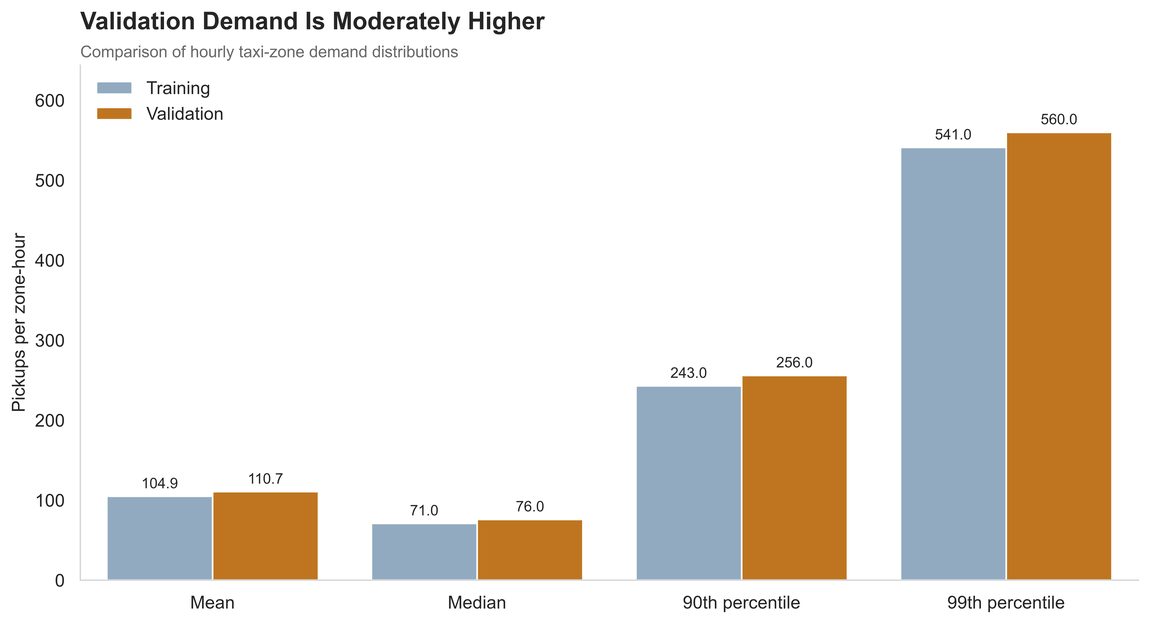

In [ ]:
# Reshaping demand statistics for comparison
demand_shift_plot = demand_shift_summary.melt(
    id_vars="dataset",
    value_vars=[
        "mean_pickups",
        "median_pickups",
        "p90",
        "p99",
    ],
    var_name="statistic",
    value_name="pickups",
)

demand_shift_plot["statistic"] = demand_shift_plot["statistic"].map({
    "mean_pickups": "Mean",
    "median_pickups": "Median",
    "p90": "90th percentile",
    "p99": "99th percentile",
})

# Visualizing target-distribution shift
fig, ax = plt.subplots(figsize=(10, 5.5))

sns.barplot(
    data=demand_shift_plot,
    x="statistic",
    y="pickups",
    hue="dataset",
    palette={
        "Training": "#8AAAC8",
        "Validation": "#D97706",
    },
    ax=ax,
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f",
        padding=3,
        fontsize=9,
    )

ax.set_title(
    "Validation Demand Is Moderately Higher",
    loc="left",
    fontsize=15,
    fontweight="bold",
    pad=22,
)

ax.text(
    0,
    1.015,
    "Comparison of hourly taxi-zone demand distributions",
    transform=ax.transAxes,
    fontsize=10,
    color="dimgray",
    ha="left",
)

ax.set(
    xlabel=None,
    ylabel="Pickups per zone-hour",
)

ax.set_ylim(
    0,
    demand_shift_plot["pickups"].max() * 1.15,
)

ax.legend(title=None)
sns.despine()
plt.tight_layout()
plt.show()

In [ ]:
# Calculating monthly demand for sufficiently represented months
monthly_demand_shift = duckdb_connection.execute("""
    WITH combined_demand AS (
        SELECT
            'Training' AS dataset,
            target_hour_utc,
            total_pickups
        FROM training_demand

        UNION ALL

        SELECT
            'Validation' AS dataset,
            target_hour_utc,
            total_pickups
        FROM validation_demand
    )

    SELECT
        dataset,
        DATE_TRUNC(
            'month',
            target_hour_utc
        ) AS target_month,
        COUNT(DISTINCT target_hour_utc)
            AS represented_hours,
        ROUND(
            AVG(total_pickups),
            2
        ) AS mean_pickups,
        MEDIAN(total_pickups) AS median_pickups
    FROM combined_demand
    GROUP BY
        dataset,
        target_month
    HAVING COUNT(DISTINCT target_hour_utc) >= 480
    ORDER BY target_month
""").df()

display(monthly_demand_shift)

,dataset,target_month,represented_hours,mean_pickups,median_pickups
0,Training,2024-08-01 00:00:00+00:00,520,94.910,65.000
1,Training,2024-09-01 00:00:00+00:00,720,101.730,67.000
2,Training,2024-10-01 00:00:00+00:00,744,102.020,67.000
3,Training,2024-11-01 00:00:00+00:00,720,105.430,70.000
4,Training,2024-12-01 00:00:00+00:00,744,107.180,72.000
5,Training,2025-01-01 00:00:00+00:00,744,104.670,69.000
6,Training,2025-02-01 00:00:00+00:00,672,109.440,72.000
7,Training,2025-03-01 00:00:00+00:00,744,105.500,72.000
8,Training,2025-04-01 00:00:00+00:00,720,104.210,70.000
9,Training,2025-05-01 00:00:00+00:00,744,107.510,73.000


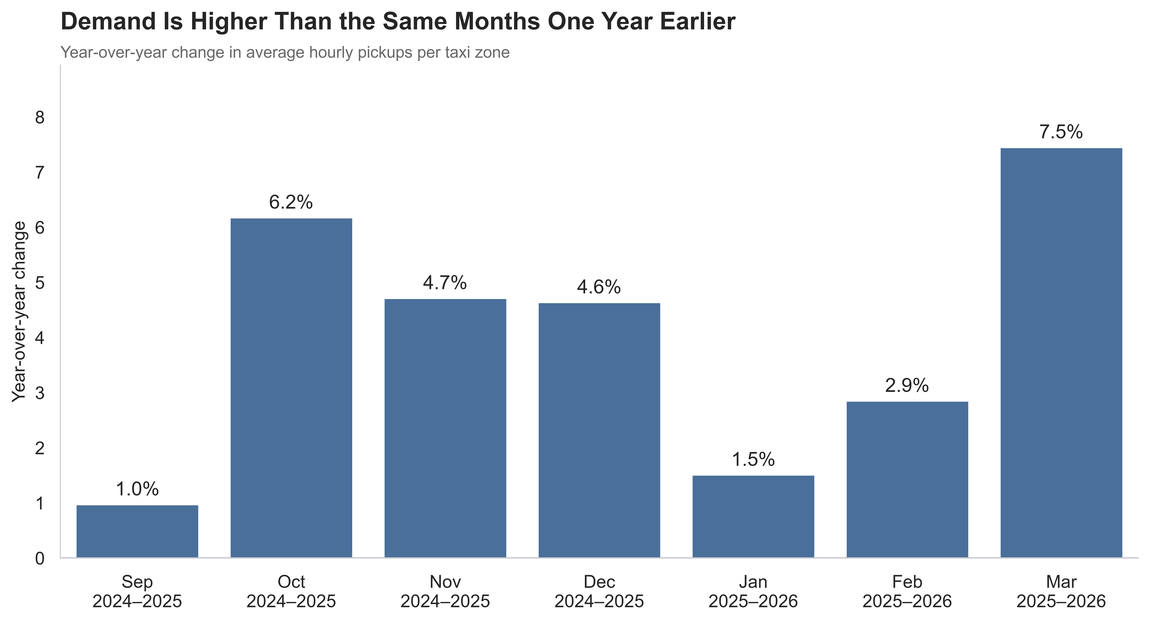

In [ ]:
# Extracting calendar year and month
monthly_yoy = monthly_demand_shift.copy()

monthly_yoy["year"] = (
    monthly_yoy["target_month"].dt.year
)

monthly_yoy["calendar_month"] = (
    monthly_yoy["target_month"].dt.month
)

# Preparing the previous-year values
previous_year = monthly_yoy[
    [
        "year",
        "calendar_month",
        "represented_hours",
        "mean_pickups",
    ]
].copy()

previous_year["year"] += 1

previous_year = previous_year.rename(columns={
    "represented_hours": "previous_hours",
    "mean_pickups": "previous_mean",
})

# Matching each month with the same month one year earlier
year_over_year_demand = monthly_yoy.merge(
    previous_year,
    on=["year", "calendar_month"],
    how="inner",
)

# Keeping months with comparable time coverage
year_over_year_demand = year_over_year_demand[
    (
        year_over_year_demand["represented_hours"]
        - year_over_year_demand["previous_hours"]
    ).abs() <= 24
].copy()

# Calculating year-over-year demand growth
year_over_year_demand["change_percent"] = (
    100
    * (
        year_over_year_demand["mean_pickups"]
        - year_over_year_demand["previous_mean"]
    )
    / year_over_year_demand["previous_mean"]
)

month_names = {
    1: "Jan", 2: "Feb", 3: "Mar",
    4: "Apr", 5: "May", 6: "Jun",
    7: "Jul", 8: "Aug", 9: "Sep",
    10: "Oct", 11: "Nov", 12: "Dec",
}

year_over_year_demand["comparison"] = (
    year_over_year_demand["calendar_month"]
    .map(month_names)
    + "\n"
    + (year_over_year_demand["year"] - 1).astype(str)
    + "–"
    + year_over_year_demand["year"].astype(str)
)

# Visualizing year-over-year demand growth
fig, ax = plt.subplots(figsize=(10, 5.5))

sns.barplot(
    data=year_over_year_demand,
    x="comparison",
    y="change_percent",
    color="#3B6EA8",
    ax=ax,
)

ax.bar_label(
    ax.containers[0],
    fmt="%.1f%%",
    padding=3,
)

ax.axhline(
    0,
    color="gray",
    linewidth=1,
)

ax.set_title(
    "Demand Is Higher Than the Same Months One Year Earlier",
    loc="left",
    fontsize=15,
    fontweight="bold",
    pad=22,
)

ax.text(
    0,
    1.015,
    "Year-over-year change in average hourly pickups per taxi zone",
    transform=ax.transAxes,
    fontsize=10,
    color="dimgray",
    ha="left",
)

ax.set(
    xlabel=None,
    ylabel="Year-over-year change",
)

ax.set_ylim(
    0,
    year_over_year_demand["change_percent"].max() * 1.2,
)

sns.despine()
plt.tight_layout()
plt.show()

### Are there more pickups in the later period?

Validation pickups are about 5.5% higher on average, and the same-month comparisons generally rise too. A model that learns only fixed location and calendar averages could lag behind that growth. I'll keep the chronological split and see whether the historical pickup features help it adapt.


In [ ]:
# Comparing hourly demand between training and validation
hourly_demand_shift = duckdb_connection.execute("""
    WITH combined_demand AS (
        SELECT
            'Training' AS dataset,
            hour_of_day,
            total_pickups
        FROM training_demand

        UNION ALL

        SELECT
            'Validation' AS dataset,
            hour_of_day,
            total_pickups
        FROM validation_demand
    ),

    hourly_summary AS (
        SELECT
            dataset,
            hour_of_day,
            AVG(total_pickups) AS mean_pickups
        FROM combined_demand
        GROUP BY
            dataset,
            hour_of_day
    )

    SELECT
        hour_of_day,
        ROUND(
            MAX(mean_pickups) FILTER (
                WHERE dataset = 'Training'
            ),
            2
        ) AS training_mean,
        ROUND(
            MAX(mean_pickups) FILTER (
                WHERE dataset = 'Validation'
            ),
            2
        ) AS validation_mean,
        ROUND(
            100.0 * (
                MAX(mean_pickups) FILTER (
                    WHERE dataset = 'Validation'
                )
                -
                MAX(mean_pickups) FILTER (
                    WHERE dataset = 'Training'
                )
            )
            /
            MAX(mean_pickups) FILTER (
                WHERE dataset = 'Training'
            ),
            2
        ) AS change_percent
    FROM hourly_summary
    GROUP BY hour_of_day
    ORDER BY hour_of_day
""").df()

display(hourly_demand_shift)

,hour_of_day,training_mean,validation_mean,change_percent
0,0,91.130,90.640,-0.540
1,1,63.820,63.940,0.190
2,2,45.900,46.180,0.610
3,3,37.050,38.130,2.910
4,4,39.050,39.710,1.680
5,5,45.930,48.140,4.800
6,6,70.680,75.520,6.850
7,7,105.260,113.490,7.820
8,8,127.730,140.600,10.080
9,9,119.140,130.170,9.260


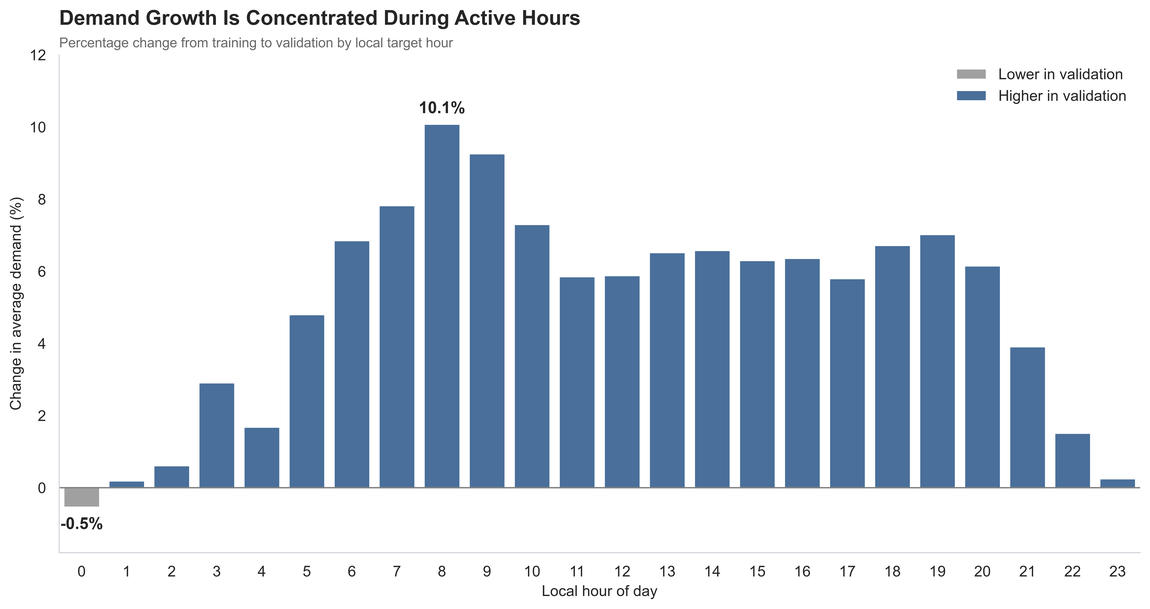

In [ ]:
# Classifying the direction of hourly change
hourly_demand_shift["direction"] = np.where(
    hourly_demand_shift["change_percent"] >= 0,
    "Higher in validation",
    "Lower in validation",
)

# Visualizing hourly distribution shift
fig, ax = plt.subplots(figsize=(12, 6.5))

sns.barplot(
    data=hourly_demand_shift,
    x="hour_of_day",
    y="change_percent",
    hue="direction",
    palette={
        "Higher in validation": "#3B6EA8",
        "Lower in validation": "#A0A0A0",
    },
    dodge=False,
    ax=ax,
)

ax.axhline(
    0,
    color="gray",
    linewidth=1,
)

# Identifying the largest and smallest changes
largest_change = hourly_demand_shift.loc[
    hourly_demand_shift["change_percent"].idxmax()
]

smallest_change = hourly_demand_shift.loc[
    hourly_demand_shift["change_percent"].idxmin()
]

ax.annotate(
    f'{largest_change["change_percent"]:.1f}%',
    xy=(
        largest_change["hour_of_day"],
        largest_change["change_percent"],
    ),
    xytext=(0, 8),
    textcoords="offset points",
    ha="center",
    fontweight="bold",
)

ax.annotate(
    f'{smallest_change["change_percent"]:.1f}%',
    xy=(
        smallest_change["hour_of_day"],
        smallest_change["change_percent"],
    ),
    xytext=(0, -16),
    textcoords="offset points",
    ha="center",
    fontweight="bold",
)

# Adding space above and below the bars
ax.set_ylim(-1.8, 12.0)

ax.set_title(
    "Demand Growth Is Concentrated During Active Hours",
    loc="left",
    fontsize=15,
    fontweight="bold",
    pad=22,
)

ax.text(
    0,
    1.015,
    "Percentage change from training to validation by local target hour",
    transform=ax.transAxes,
    fontsize=10,
    color="dimgray",
    ha="left",
)

ax.set(
    xlabel="Local hour of day",
    ylabel="Change in average demand (%)",
)

ax.legend(title=None)
sns.despine()
plt.tight_layout(pad=1.5)
plt.show()

### Which hours changed the most?

The increase is not evenly spread across the day. It is strongest around the morning commute and much smaller overnight. A single upward correction could therefore overshoot quiet hours while still missing the morning peak.


In [ ]:
# Comparing weather missingness across data splits
weather_missingness_shift = duckdb_connection.execute("""
    SELECT
        'Training' AS dataset,
        ROUND(
            100.0 * AVG(
                CASE
                    WHEN weather_forecast_has_missing
                        THEN 1
                    ELSE 0
                END
            ),
            3
        ) AS any_weather_missing_percent
    FROM training_forecast_rows

    UNION ALL

    SELECT
        'Validation',
        ROUND(
            100.0 * AVG(
                CASE
                    WHEN weather_forecast_has_missing
                        THEN 1
                    ELSE 0
                END
            ),
            3
        )
    FROM validation_forecast_rows
""").df()

display(weather_missingness_shift)

,dataset,any_weather_missing_percent
0,Training,0.983
1,Validation,0.000


### Did weather coverage change too?

Weather coverage improves rather than deteriorates in validation: it has no missing values in these checks. That removes one possible explanation for later errors, but also means validation alone is not a strong test of performance during missing-weather periods.


## Questions to take into modeling

The main story is taking shape. Weekly history is a strong starting point, but activity differs sharply across locations and hours, and the lags miss unusual surges. A few very quiet zones need their own evaluation because they account for most zeros.

I'll take these questions into modeling: does boosting improve on the weekly reference, do event flags help when they are relevant, and where does underprediction remain? I'll retain missing weather for models that support it and learn any necessary imputation from training only. EDA helps choose those comparisons; the later predictions will decide which choices are worth keeping.

In the [modeling notebook](04_production_modeling_refactored_v2.ipynb), I start with the weekly baseline and look at where the fitted models improve on it. The [archived weather checks](03_archived_weather_forecast_production_updated.ipynb) explain how each weather run was selected.
